### Cell 1

In [2]:
import os
import glob
from PIL import Image
import shutil
import numpy as np
import cv2
import pandas as pd
import warnings
import shutil
warnings.simplefilter("ignore")
import tensorflow.keras.layers as Layers
import tensorflow.keras.activations as Actications
import tensorflow.keras.models as Models
import tensorflow.keras.optimizers as Optimizer
import tensorflow.keras.metrics as Metrics
import tensorflow.keras.utils as Utils
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix as CM
from random import randint
import matplotlib.gridspec as gridspec
from tensorflow.keras.models import model_from_json
import glob,os.path
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Input, Conv2D,Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from IPython.display import clear_output
import random, re, math
import tensorflow.keras.backend as K
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import zipfile
from tensorflow.keras.models import model_from_json
from datetime import datetime
import mysql.connector 
import threading
import time


<span style="color:green"><font size="3">Cell 2: Load all models and for predictions and secondary functions</span>.

In [3]:
os.chdir('/home/castrone/PRIMUS/data/83_BIOINFORMATICS/Julia/Python') 
#NN_model_classify_head_slice1


json_file_head_slice = open('NN_model_classify_head_slice1.json', 'r')
loaded_model_json_head_slice = json_file_head_slice.read()
json_file_head_slice.close()

loaded_model_head_slice = model_from_json(loaded_model_json_head_slice)
loaded_model_head_slice.load_weights("NN_model_classify_head_slice1.h5")
print("Model for head slice classification was loadded!")

json_file_masking = open('NN_model_masking_final.json', 'r')
loaded_model_json_masking = json_file_masking.read()
json_file_masking.close()
loaded_model_masking = model_from_json(loaded_model_json_masking)
# load weights into new model
loaded_model_masking.load_weights("NN_model_masking_final.h5")
print("Model for masking was loadded!")


json_file_head_slice_1176 = open('NN_model_classify_head_1176_retrained.json', 'r')
loaded_model_json_head_slice_1176 = json_file_head_slice_1176.read()
json_file_head_slice_1176.close()

loaded_model_head_slice_1176 = model_from_json(loaded_model_json_head_slice_1176)
loaded_model_head_slice_1176.load_weights("NN_model_classify_head_1176_retrained.h5")
print("Model for head slice 1176 classification was loadded!")

json_file_masking_1176 = open('NN_model_masking_1176.json', 'r')
loaded_model_json_masking_1176 = json_file_masking_1176.read()
json_file_masking_1176.close()
loaded_model_masking_1176 = model_from_json(loaded_model_json_masking_1176)
# load weights into new model
loaded_model_masking_1176.load_weights("NN_model_masking_1176.h5")
print("Model for masking 1176 was loadded!")

json_file_holder_masking_1176 = open('NN_model_masking_right_holder_1176.json', 'r')
loaded_model_json_holder_masking_1176 = json_file_holder_masking_1176.read()
json_file_holder_masking_1176.close()
loaded_model_holder_masking_1176 = model_from_json(loaded_model_json_holder_masking_1176)
# load weights into new model
loaded_model_holder_masking_1176.load_weights("NN_model_masking_right_holder_1176.h5")
print("Model for holder masking was loadded!")

AUTO = tf.data.experimental.AUTOTUNE

# Configuration
IMAGE_SIZE = [256, 256]
EPOCHS = 40
SEED = 777
BATCH_SIZE = 16 

def creat_dataframe(img_path):
    os.chdir(img_path)
    thisdir = os.getcwd()
    im_paths=[]
    im_ids=[]
    for r, d, f in os.walk(thisdir):
        for file in f:
            if file.endswith('.bmp'):
                path = os.path.join(r, file)  
                im_paths.append(path)
                im_id = file.split(".")[0]
                im_ids.append(im_id)

    df=pd.DataFrame(data = {"id": im_ids, "img_path": im_paths})
    return df

def read_image_and_mask(image_path, mask_path=None,resize=IMAGE_SIZE):
    
    image=tf.io.read_file(image_path)
    image=tf.image.decode_bmp(image, channels=3)
    image=tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, dtype=tf.float32)/255.
    return image


def get_validation_dataset(df):
  
    validation_dataset = tf.data.Dataset.from_tensor_slices(df["img_path"].values)
    validation_dataset = validation_dataset.map(read_image_and_mask)
    validation_dataset = validation_dataset.batch(BATCH_SIZE)
  

    return validation_dataset


def get_contour_areas(contours):
    all_areas= []
    for cnt in contours:
        area= cv2.contourArea(cnt)
        all_areas.append(area)
    return all_areas


Model for head slice classification was loadded!
Model for masking was loadded!
Model for head slice 1176 classification was loadded!
Model for masking 1176 was loadded!
Model for holder masking was loadded!


<span style="color:black"><font size="5">Cell 3: CHECK new scanner, old scanner or died mice</span>.

In [4]:
def new_old_scanner_check(parent):
    df = pd.DataFrame(columns = ['ID', 'SCANNER', 'PATH', 'IMAGE_WIDTH', 'IMAGE_HEIGHT'])
    ID = []
    scanner = []
    path = []
    image_width = []
    image_height = []
    split = []
    id_mouse = ''
    
    df_died = pd.DataFrame(columns = ['ID', 'SCANNER', 'PATH', 'IMAGE_WIDTH', 'IMAGE_HEIGHT'])
    ID_died = []
    scanner_died = []
    path_died = []
    image_width_died = []
    image_height_died = []
    id_mouse_died = ''
    
    isExist = os.path.exists(cohort_folder+'/'+'csv_files_check_new_old')
    if not isExist:
        os.mkdir(cohort_folder+'/'+'csv_files_check_new_old')
        
        
    for file_name in sorted(os.listdir(parent)):
        if file_name == 'Ignore':
            continue
        
        if file_name.endswith('body') or file_name.endswith('fantom1') or file_name.endswith('fantom2') or file_name.endswith('RecDXA') or file_name.endswith('mask') or file_name.endswith('Morphology') or file_name.endswith('head') or file_name.endswith('mask_edited') or file_name.endswith('predictions'):
            continue
            
        if file_name.endswith('+'):
            id_mouse_died= file_name.split('+')[0]
            ID_died.append(id_mouse_died)  
            scanner_died.append("DIED")
            path = "".join((parent,'/', file_name))
            path_died.append(path)
            image_width_died.append(None)
            image_height_died.append(None)
            
        if len(ID_died)>0:
            df_died['ID']=ID_died[:1]
            df_died['SCANNER']=scanner_died[:1]
            df_died['PATH']=path_died[:1]
            df_died['IMAGE_WIDTH']=image_width_died[:1]
            df_died['IMAGE_HEIGHT']=image_height_died[:1]
            df_died.to_csv(cohort_folder+'/'+'csv_files_check_new_old'+'/'+id_mouse_died+'+'+'.csv',index=False)   
            
        if file_name.endswith('.bmp') and 'VOI' not in parent and '_without_fantoms' not in parent:
            im = cv2.imread(parent + '/' + file_name)
            h, w, c = im.shape
            split= file_name.split('_')
            id_mouse = file_name.split('rec')[0]
            id_mouse = id_mouse.split('__')[0]
            
            image_width.append(w)
            image_height.append(h)
            #print(id_mouse)
            
            if ("IR" in split):
                ID.append(id_mouse)  
                scanner.append(1176)
                path.append(parent)
                
            else:
                ID.append(id_mouse)  
                scanner.append(1278)
                path.append(parent)
               
         
                  
    
    
           
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                new_old_scanner_check(current_path)
            else:
                continue 
             
    
    
    if len(ID)>0:

        df['ID']=ID[:1]
        df['SCANNER']=scanner[:1]
        df['PATH']=path[:1]
        df['IMAGE_WIDTH']=image_width[:1]
        df['IMAGE_HEIGHT']=image_height[:1]
        print(df)
   
    if len(df)>0:
        df.to_csv(cohort_folder+'/'+'csv_files_check_new_old'+'/'+id_mouse+'.csv',index=False)      
        
        
    
    

<span style="color:red"><font size="3">Cell 4: Change cohort folder!!! RUN THIS EVERY COHORT</span>.

In [103]:
#cohort_folder='/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt'
cohort_folder = '/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt'
cohort_number = cohort_folder.split('c')[3] # Change here in case your username does not have a 'c'
cohort_number = cohort_number.split('_')[0]
cohort_number = 'c'+ cohort_number
print('Cohort folder:',cohort_folder)
print('Cohort number:',cohort_number)

Cohort folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt
Cohort number: c188


### Cell 5: RUN THIS EVERY COHORT

In [ ]:
new_old_scanner_check(cohort_folder)
print("done")
#find all csv files
all_files = glob.glob(os.path.join(cohort_folder+'/'+'csv_files_check_new_old', "*.csv"))
##create one dataframe with all csv files
df_from_each_file = (pd.read_csv(f, sep=',') for f in all_files)
df_cohort   = pd.concat(df_from_each_file, ignore_index=True)
#create one csv file
df_cohort.to_csv(cohort_folder+'/'+"Check_1278_1176_died.csv",index=False)
#shutil.rmtree(cohort_folder+'/'+'csv_files_check_new_old')

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Fam53a_M_E64-F9375
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Fam53a_M_E64-F9375/Fam53a_M_E64-F9375_Rec
                   ID  SCANNER  \
0  Fam53a_M_E64-F9375     1278   

                                                PATH  IMAGE_WIDTH  \
0  /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...          848   

   IMAGE_HEIGHT  
0           848  
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Fam53a_M_E64-F9375/VOI
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Fam53a_M_E64-F9375/VOI(1)
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Slc38a8KO_F_E64-F9273+
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Slc38a8KO_F_E64-F9275
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Slc38a8KO_F_E64-F9275/Slc38a8KO_F_E64-F9275_Rec
                      ID  SCANNER  \
0  Slc38a8KO_F_E64-F9275     1278   

                                                PATH  IMAGE_WIDTH  \
0  /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...          848   

   IMAGE_HEIGHT  
0           848  
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Slc38a8KO_F_E64-F9276
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCRE

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9330
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9330/Sox14HET_F_E64-F9330_Rec
                     ID  SCANNER  \
0  Sox14HET_F_E64-F9330     1176   

                                                PATH  IMAGE_WIDTH  \
0  /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...          932   

   IMAGE_HEIGHT  
0           920  
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9266
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9266/Sox14HET_M_E64-F9266_Rec
                     ID  SCANNER  \
0 

### Cell 6: RUN THIS EVERY COHORT

In [104]:
df_cohort = pd.read_csv(cohort_folder+'/'+"Check_1278_1176_died.csv")
df_cohort.sort_values(by=['ID'], inplace=True)
df_cohort

,ID,SCANNER,PATH,IMAGE_WIDTH,IMAGE_HEIGHT
22,Fam53a_M_E64-F9375,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
23,Fam53a_M_E64-F9376,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
30,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
2,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
5,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
32,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
18,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
44,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
39,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN
40,Fam53a_M_E64-F9377,DIED,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,NaN,NaN


### Cell 7: RUN THIS EVERY COHORT - If needed, change '1278' or '1176' to 1278 or 1176

In [127]:
df_cohort["IMAGE_WIDTH"] = pd.to_numeric(df_cohort["IMAGE_WIDTH"])
df_cohort["IMAGE_HEIGHT"] = pd.to_numeric(df_cohort["IMAGE_HEIGHT"])
df_cohort_1278 = df_cohort.loc[df_cohort['SCANNER']=='1278'] # If df_cohort_1278 is empty, change the '' situation
df_cohort_1176 = df_cohort.loc[df_cohort['SCANNER']=='1176'] # If df_cohort_1176 is empty, change the '' situation
print('Data Frame for Scanner 1176')
display(df_cohort_1176)
print('Data Frame for Scanner 1278')
display(df_cohort_1278)
df_cohort_1176['ID_without'] = df_cohort_1176.ID.str.split('_').str[2]


Data Frame for Scanner 1176


,ID,SCANNER,PATH,IMAGE_WIDTH,IMAGE_HEIGHT
24,Krtap9-5_F_E64-F9384_IR_,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,940.0
36,Krtap9-5_F_E64-F9410,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,972.0
0,Krtap9-5_M_E64-F9404_IR_,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,948.0
49,Sox14HET_F_E64-F9317,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,964.0
26,Sox14HET_F_E64-F9330,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,920.0
20,Sox14HET_M_E64-F9266,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,940.0
15,Sox14HET_M_E64-F9280,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,972.0
17,Sox14HET_M_E64-F9281,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,964.0
41,Sox14HET_M_E64-F9282,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,984.0
43,Sox14HET_M_E64-F9297,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,944.0


Data Frame for Scanner 1278


,ID,SCANNER,PATH,IMAGE_WIDTH,IMAGE_HEIGHT
22,Fam53a_M_E64-F9375,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
23,Fam53a_M_E64-F9376,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
19,Fam53a_M_E64-F9378,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
1,Fam53a_M_E64-F9379,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
4,Ror1_F_E64-F9228,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
25,Ror1_M_E64-F9224,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
52,Ror1_M_E64-F9225,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
31,Slc38a8KO_F_E64-F9272,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
14,Slc38a8KO_F_E64-F9275,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
28,Slc38a8KO_F_E64-F9276,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0


### Cell 8: RUN THIS EVERY COHORT - Check if you need to remove items from the dataframe and if they are complete

In [128]:
#df_cohort_1176 = df_cohort_1176.iloc[5], df_cohort_1176.iloc[11] # if you want to get specific elements, use iloc, like this line

redo = ['wt_M_82Z-06626', 'Fam53a_M_E64-F9379']
df_cohort_1278 =df_cohort_1278[df_cohort_1278['ID'].isin(redo)]


#df_cohort_1278 = df_cohort_1278.loc[df_cohort_1278['ID'] == '*.bmp'] # You can use this syntax to get all elements that don't have (!=) or have (==) one specific ID, IMAGE_WIDHT, IMAGE_HEIGHT


#df_cohort_1278 = df_cohort_1278[-2:-1] # This line will return the cohort elements until the 6th element. 
# You can also use something like df_cohort_1278 = df_cohort_1278[:-1] to return all elements, except the last.
# The syntax is this: df_cohort_1278['starting element (included)':'last element (excluded)']

#df_cohort_1278 = pd.concat([df_cohort_1278[:11], df_cohort_1278[14:]]) # run this to join different slices of the dataframe
# You can join more than two slices, just put them inside the [ ]. Like so: pd.concat([df_cohort_1278[:5], df_cohort_1278[7:15], df_cohort_1278[18:22], df_cohort_1278[25:-1]])

display(df_cohort_1278) # Use this line to show the df_cohort_1278 below
#df_cohort_1176 = df_cohort_1176[-1:] # Just like df_cohort_1278

#df_cohort_1176 = pd.concat([df_cohort_1176[1:2], df_cohort_1176[3:]]) # Just like df_cohort_1278

display(df_cohort_1176) # Use this line to show the df_cohort_1176 below

,ID,SCANNER,PATH,IMAGE_WIDTH,IMAGE_HEIGHT
1,Fam53a_M_E64-F9379,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0
8,wt_M_82Z-06626,1278,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,848.0,848.0


,ID,SCANNER,PATH,IMAGE_WIDTH,IMAGE_HEIGHT,ID_without
24,Krtap9-5_F_E64-F9384_IR_,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,940.0,E64-F9384
36,Krtap9-5_F_E64-F9410,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,972.0,E64-F9410
0,Krtap9-5_M_E64-F9404_IR_,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,948.0,E64-F9404
49,Sox14HET_F_E64-F9317,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,964.0,E64-F9317
26,Sox14HET_F_E64-F9330,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,920.0,E64-F9330
20,Sox14HET_M_E64-F9266,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,940.0,E64-F9266
15,Sox14HET_M_E64-F9280,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,972.0,E64-F9280
17,Sox14HET_M_E64-F9281,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,964.0,E64-F9281
41,Sox14HET_M_E64-F9282,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,984.0,E64-F9282
43,Sox14HET_M_E64-F9297,1176,/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima...,932.0,944.0,E64-F9297


# Cell 9: 1278 - RUN THIS FOR EVERY COHORT THAT HAS 1278 ANIMALS

In [ ]:
'''print('############## Part 1: function to detect the phantoms - Running ###########')
init = time.time()

visited_path = []
failed_path = []
for path in df_cohort_1278['PATH']:
    
    try:
        isExist = os.path.exists(cohort_folder+'/'+'csv_files')
        if not isExist:
            os.mkdir(cohort_folder+'/'+'csv_files')
        detect_circle(path)
    except Exception:
        animal = df_cohort_1278.loc[df_cohort_1278['PATH'] == path]
        print(f'%%%%%%%ISSUE ON THE FOLLOWING ANIMAL DURING PHATOM DETECTION: \n%%%%%%% {animal}')

all_files = glob.glob(os.path.join(cohort_folder+'/'+'csv_files', "*.csv"))
df_from_each_file = (pd.read_csv(f, sep=',') for f in all_files)
df_merged   = pd.concat(df_from_each_file, ignore_index=True)
df_merged.to_csv(cohort_folder+'/'+"fantoms_count.csv",index=False)
shutil.rmtree(cohort_folder+'/'+'csv_files')

end = time.time()'''
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 1 - Finished ###########')


for path in df_cohort_1278['PATH']:
    
    
    
    
    try:
        print('############## Part 2: function to predict the head slice - Running ###########')
        init = time.time()
        
        predict_head_slice_1278(path)
        

        end = time.time()
        print("############################This step took " + str(end-init) + " seconds###########################")
        print('############## Part 2 - Finished ###########')


        print('############## Part 3: function for masking body without head - Running ###########')
        init = time.time()


        selected_row = df_cohort_1278.loc[df_cohort_1278['PATH'] == path]
        masking_predict_1278(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT']))

        end = time.time()
        print("############################This step took " + str(end-init) + " seconds###########################")
        print('############## Part 3 - Finished ###########')


        print('############## Part 4: function for masking fantoms to get ROI - Running ###########')
        init = time.time()


        mask_fantoms(path)  

        end = time.time()
        print("############################This step took " + str(end-init) + " seconds###########################")
        print('############## Part 4 - Finished ###########')


        print('############## Part 5: function for BMD and TMD calculation - Running ###########')
        init = time.time()


        isBMD_TMD = os.path.exists(cohort_folder+'/'+'BMD_TMD') 
        if not isBMD_TMD:
            os.mkdir(cohort_folder+'/'+'BMD_TMD')
        TMD_BMD_1278(path)

        end = time.time()
        print("############################This step took " + str(end-init) + " seconds###########################")
        print('############## Part 5 - Finished ###########')
    except Exception:
        animal = df_cohort_1278.loc[df_cohort_1278['PATH'] == path]
        print(f'%%%%%%%ISSUE ON THE FOLLOWING ANIMAL: \n%%%%%%% {animal}')

############################This step took -305153.94289827347 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function to predict the head slice - Running ###########


# Cell 10: 1176 - RUN THIS FOR EVERY COHORT THAT HAS 1176 ANIMALS

############## Part 1: function to predict the head slice - Running ###########
                                Image_name  Propability
0     Krtap9-5_F_E64-F9410__IR_rec0108.bmp     0.499817
1     Krtap9-5_F_E64-F9410__IR_rec0109.bmp     0.499365
2     Krtap9-5_F_E64-F9410__IR_rec0110.bmp     0.499499
3     Krtap9-5_F_E64-F9410__IR_rec0111.bmp     0.499845
4     Krtap9-5_F_E64-F9410__IR_rec0112.bmp     0.500274
...                                    ...          ...
2757  Krtap9-5_F_E64-F9410__IR_rec2865.bmp     0.499942
2758  Krtap9-5_F_E64-F9410__IR_rec2866.bmp     0.499234
2759  Krtap9-5_F_E64-F9410__IR_rec2867.bmp     0.499549
2760  Krtap9-5_F_E64-F9410__IR_rec2868.bmp     0.498286
2761  Krtap9-5_F_E64-F9410__IR_rec_spr.bmp     0.296826

[2762 rows x 2 columns]
MAX Propability is  0.9403194189071655
Path to image: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Krtap9-5_F_E64-F9410/Krt

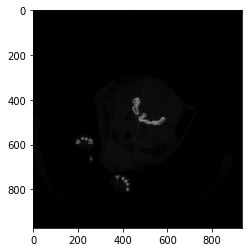

Index of predicted head slice: 607
Count of head images: 607
Count of body images: 2155
Folders were created
Images were copied to the new folders
############################This step took 680.2921469211578 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Krtap9-5_F_E64-F9410/Krtap9-5_F_E64-F9410_Rec/Krtap9-5_F_E64-F9410__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Krtap9-5_F_E64-F9410/Krtap9-5_F_E64-F9410_Rec/Krtap9-5_F_E64-F9410__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Krtap9-5_F_E64-F9410/Krtap9-5_F_E64-F94

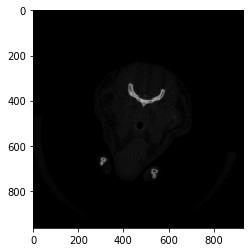

Index of predicted head slice: 565
Count of head images: 565
Count of body images: 2121
Folders were created
Images were copied to the new folders
############################This step took 639.8675537109375 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9317/Sox14HET_F_E64-F9317_Rec/Sox14HET_F_E64-F9317__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9317/Sox14HET_F_E64-F9317_Rec/Sox14HET_F_E64-F9317__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9317/Sox14HET_F_E64-F93

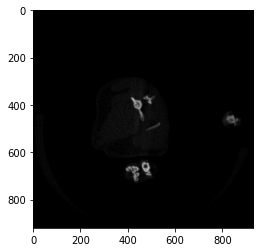

Index of predicted head slice: 2204
Count of head images: 2204
Count of body images: 493
Folders were created
Images were copied to the new folders
############################This step took 616.3801743984222 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9330/Sox14HET_F_E64-F9330_Rec/Sox14HET_F_E64-F9330__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9330/Sox14HET_F_E64-F9330_Rec/Sox14HET_F_E64-F9330__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_F_E64-F9330/Sox14HET_F_E64-F9

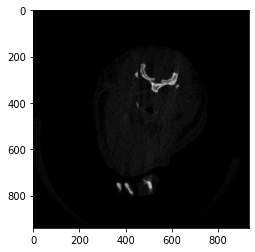

Index of predicted head slice: 453
Count of head images: 453
Count of body images: 2262
Folders were created
Images were copied to the new folders
############################This step took 648.9557621479034 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9266/Sox14HET_M_E64-F9266_Rec/Sox14HET_M_E64-F9266__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9266/Sox14HET_M_E64-F9266_Rec/Sox14HET_M_E64-F9266__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9266/Sox14HET_M_E64-F92

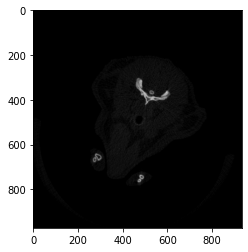

Index of predicted head slice: 620
Count of head images: 620
Count of body images: 2208
Folders were created
Images were copied to the new folders
############################This step took 625.5869619846344 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9280/Sox14HET_M_E64-F9280_Rec/Sox14HET_M_E64-F9280__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9280/Sox14HET_M_E64-F9280_Rec/Sox14HET_M_E64-F9280__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9280/Sox14HET_M_E64-F92

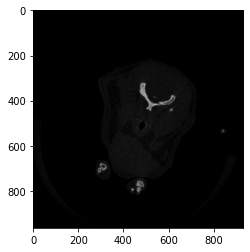

Index of predicted head slice: 543
Count of head images: 543
Count of body images: 2104
Folders were created
Images were copied to the new folders
############################This step took 569.5395867824554 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9281/Sox14HET_M_E64-F9281_Rec/Sox14HET_M_E64-F9281__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9281/Sox14HET_M_E64-F9281_Rec/Sox14HET_M_E64-F9281__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9281/Sox14HET_M_E64-F92

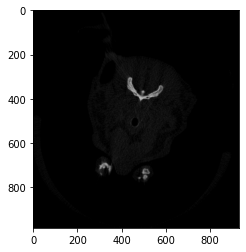

Index of predicted head slice: 596
Count of head images: 596
Count of body images: 2097
Folders were created
Images were copied to the new folders
############################This step took 563.6837649345398 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9282/Sox14HET_M_E64-F9282_Rec/Sox14HET_M_E64-F9282__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9282/Sox14HET_M_E64-F9282_Rec/Sox14HET_M_E64-F9282__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9282/Sox14HET_M_E64-F92

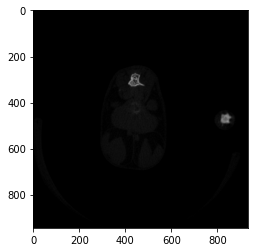

Index of predicted head slice: 2280
Count of head images: 2280
Count of body images: 543
Folders were created
Images were copied to the new folders
############################This step took 589.0676746368408 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9297/Sox14HET_M_E64-F9297_Rec/Sox14HET_M_E64-F9297__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9297/Sox14HET_M_E64-F9297_Rec/Sox14HET_M_E64-F9297__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9297/Sox14HET_M_E64-F9

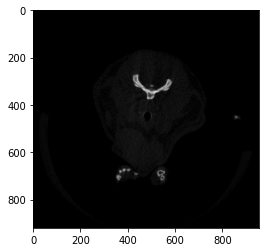

Index of predicted head slice: 572
Count of head images: 572
Count of body images: 2121
Folders were created
Images were copied to the new folders
############################This step took 772.3233716487885 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9298/Sox14HET_M_E64-F9298_Rec/Sox14HET_M_E64-F9298__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9298/Sox14HET_M_E64-F9298_Rec/Sox14HET_M_E64-F9298__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9298/Sox14HET_M_E64-F92

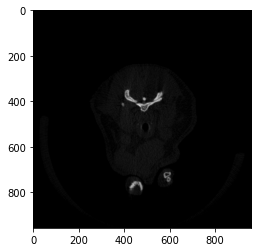

Index of predicted head slice: 576
Count of head images: 576
Count of body images: 2139
Folders were created
Images were copied to the new folders
############################This step took 615.1168310642242 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9299/Sox14HET_M_E64-F9299_Rec/Sox14HET_M_E64-F9299__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9299/Sox14HET_M_E64-F9299_Rec/Sox14HET_M_E64-F9299__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9299/Sox14HET_M_E64-F92

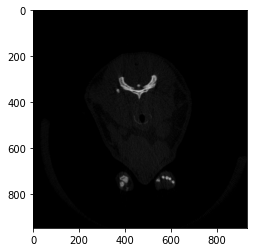

Index of predicted head slice: 529
Count of head images: 529
Count of body images: 2049
Folders were created
Images were copied to the new folders
############################This step took 521.1449983119965 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9300/Sox14HET_M_E64-F9300_Rec/Sox14HET_M_E64-F9300__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9300/Sox14HET_M_E64-F9300_Rec/Sox14HET_M_E64-F9300__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14HET_M_E64-F9300/Sox14HET_M_E64-F93

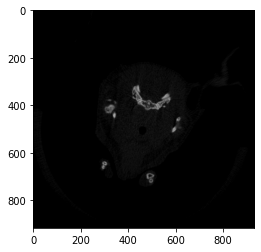

Index of predicted head slice: 595
Count of head images: 595
Count of body images: 1848
Folders were created
Images were copied to the new folders
############################This step took 488.58021569252014 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9267/Sox14_F_E64-F9267_Rec/Sox14_F_E64-F9267__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9267/Sox14_F_E64-F9267_Rec/Sox14_F_E64-F9267__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9267/Sox14_F_E64-F9267_Rec/Sox14_F_E64-F926

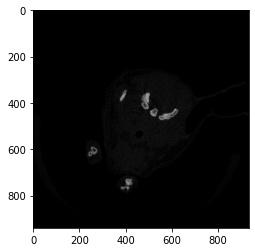

Index of predicted head slice: 577
Count of head images: 577
Count of body images: 2223
Folders were created
Images were copied to the new folders
############################This step took 584.4438464641571 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9268/Sox14_F_E64-F9268_Rec/Sox14_F_E64-F9268__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9268/Sox14_F_E64-F9268_Rec/Sox14_F_E64-F9268__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9268/Sox14_F_E64-F9268_Rec/Sox14_F_E64-F9268

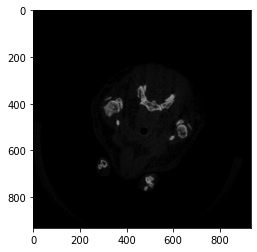

Index of predicted head slice: 561
Count of head images: 561
Count of body images: 2002
Folders were created
Images were copied to the new folders
############################This step took 533.481347322464 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9283/Sox14_F_E64-F9283_Rec/Sox14_F_E64-F9283__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9283/Sox14_F_E64-F9283_Rec/Sox14_F_E64-F9283__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9283/Sox14_F_E64-F9283_Rec/Sox14_F_E64-F9283_

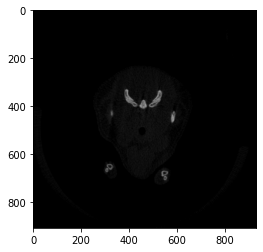

Index of predicted head slice: 542
Count of head images: 542
Count of body images: 2016
Folders were created
Images were copied to the new folders
############################This step took 525.4859335422516 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9284/Sox14_F_E64-F9284_Rec/Sox14_F_E64-F9284__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9284/Sox14_F_E64-F9284_Rec/Sox14_F_E64-F9284__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9284/Sox14_F_E64-F9284_Rec/Sox14_F_E64-F9284

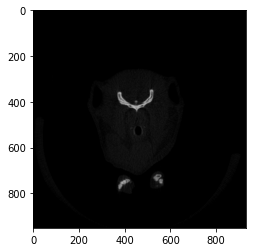

Index of predicted head slice: 544
Count of head images: 544
Count of body images: 2051
Folders were created
Images were copied to the new folders
############################This step took 514.0184555053711 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9301/Sox14_F_E64-F9301_Rec/Sox14_F_E64-F9301__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9301/Sox14_F_E64-F9301_Rec/Sox14_F_E64-F9301__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9301/Sox14_F_E64-F9301_Rec/Sox14_F_E64-F9301

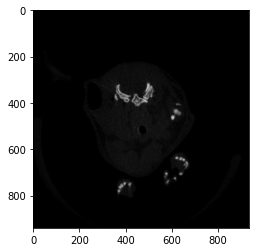

Index of predicted head slice: 535
Count of head images: 535
Count of body images: 2067
Folders were created
Images were copied to the new folders
############################This step took 517.887172460556 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9302/Sox14_F_E64-F9302_Rec/Sox14_F_E64-F9302__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9302/Sox14_F_E64-F9302_Rec/Sox14_F_E64-F9302__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9302/Sox14_F_E64-F9302_Rec/Sox14_F_E64-F9302_

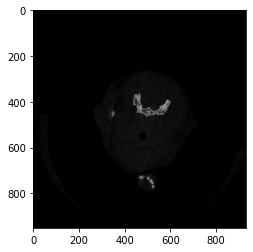

Index of predicted head slice: 569
Count of head images: 569
Count of body images: 1985
Folders were created
Images were copied to the new folders
############################This step took 530.1440949440002 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9314/Sox14_F_E64-F9314_Rec/Sox14_F_E64-F9314__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9314/Sox14_F_E64-F9314_Rec/Sox14_F_E64-F9314__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9314/Sox14_F_E64-F9314_Rec/Sox14_F_E64-F9314

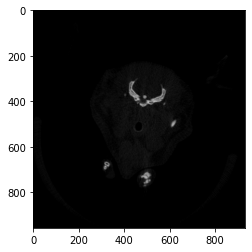

Index of predicted head slice: 571
Count of head images: 571
Count of body images: 2098
Folders were created
Images were copied to the new folders
############################This step took 559.110509634018 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9315/Sox14_F_E64-F9315_Rec/Sox14_F_E64-F9315__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9315/Sox14_F_E64-F9315_Rec/Sox14_F_E64-F9315__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9315/Sox14_F_E64-F9315_Rec/Sox14_F_E64-F9315_

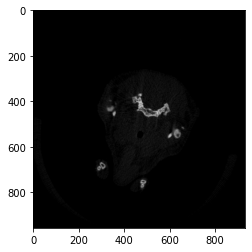

Index of predicted head slice: 600
Count of head images: 600
Count of body images: 2080
Folders were created
Images were copied to the new folders
############################This step took 567.2691030502319 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9316/Sox14_F_E64-F9316_Rec/Sox14_F_E64-F9316__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9316/Sox14_F_E64-F9316_Rec/Sox14_F_E64-F9316__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9316/Sox14_F_E64-F9316_Rec/Sox14_F_E64-F9316

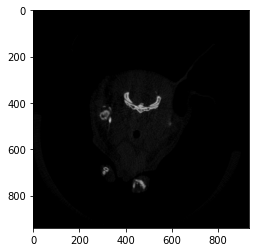

Index of predicted head slice: 593
Count of head images: 593
Count of body images: 2018
Folders were created
Images were copied to the new folders
############################This step took 537.5781784057617 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9329/Sox14_F_E64-F9329_Rec/Sox14_F_E64-F9329__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9329/Sox14_F_E64-F9329_Rec/Sox14_F_E64-F9329__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_F_E64-F9329/Sox14_F_E64-F9329_Rec/Sox14_F_E64-F9329

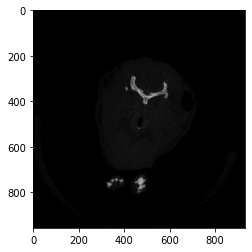

Index of predicted head slice: 513
Count of head images: 513
Count of body images: 2054
Folders were created
Images were copied to the new folders
############################This step took 530.45751953125 seconds###########################
############## Part 1 - Finished ###########
############## Part 2: function for masking body without head - Running ###########
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_M_E64-F9265/Sox14_M_E64-F9265_Rec/Sox14_M_E64-F9265__IR__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_M_E64-F9265/Sox14_M_E64-F9265_Rec/Sox14_M_E64-F9265__IR__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210426c188_Fam53a & Krtap9-5 & Ror1 & Slc38a8KO & Sox14 & wt/Sox14_M_E64-F9265/Sox14_M_E64-F9265_Rec/Sox14_M_E64-F9265__

In [122]:
for path in df_cohort_1176['PATH']:
    
    print('############## Part 1: function to predict the head slice - Running ###########')
    init = time.time()
    predict_head_slice_1176(path)
    
    end = time.time()
    print("############################This step took " + str(end-init) + " seconds###########################")
    print('############## Part 1 - Finished ###########')
    
    
    print('############## Part 2: function for masking body without head - Running ###########')
    init = time.time()

    selected_row = df_cohort_1176.loc[df_cohort_1176['PATH'] == path]
    masking_predict_1176(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT']))

    end = time.time()
    print("############################This step took " + str(end-init) + " seconds###########################")
    print('############## Part 2 - Finished ###########')
    
    
    print('############## Part 3: function to mask holder - Running ###########')
    init = time.time()

    selected_row = df_cohort_1176.loc[df_cohort_1176['PATH'] == path]
    holder_masking_predict(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT'])) 

    end = time.time()
    print("############################This step took " + str(end-init) + " seconds###########################")
    print('############## Part 3 - Finished ###########')
    
    
    print('############## Part 4: function for BMD and TMD calculation - Running ###########')
    init = time.time()

    isBMD_TMD = os.path.exists(cohort_folder+'/'+'BMD_TMD')
    if not isBMD_TMD:
        os.mkdir(cohort_folder+'/'+'BMD_TMD')
    TMD_BMD_1176(path)

    end = time.time()
    print("############################This step took " + str(end-init) + " seconds###########################")
    print('############## Part 4 - Running ###########')

### Cell 11: Run this to create the DXA file. Check if all the live animals have values and if the values are ok

In [ ]:
all_files = glob.glob(os.path.join(cohort_folder+'/'+'BMD_TMD', "*.csv")) ################# CHANGE HERE
df_from_each_file = (pd.read_csv(f, sep=',',header=0) for f in all_files)
df_merged = pd.concat(df_from_each_file, ignore_index=True)

df_merged.drop(df_merged.filter(regex="Unname"),axis=1, inplace=True)
df_merged = df_merged.sort_values(by='CCP_mouseID')
df_merged = df_merged.reset_index(drop=True)
df_merged.rename(columns = {'CCP_mouseID':'Identificator','CCP_date':'CCP_DXA_001', 'CCP_metadata':'','CCP_DXA_793_001':'','CCP_DXA_004_001':''}, inplace = True)
df_merged.loc[-1] = ['CCP_mouseID','CCP_date', 'CCP_metadata','CCP_DXA_793_001','CCP_DXA_004_001']
df_merged.index = df_merged.index + 1
df_merged.loc[-1] = ['MouseID','Date', 'MetaDatalink','TMD','BMD']
df_merged.index = df_merged.index + 1
df_merged = df_merged.sort_index()
#print(df_merged)
df_merged.to_excel(cohort_folder+'/'+'DXA '+cohort_number+'.xlsx',index=False,index_label=False)


# connect to the DB
conn = mysql.connector.connect(host='london02.img.local', port=3306, database='vestlontest', user='vestlontest_bi', password='vJPeF5T6a83j$w8N')
cursor = conn.cursor()
sql= "SELECT * FROM MOUSE WHERE COHORT_ID ='%s'"%(cohort_number)
cursor.execute(sql)
database=pd.DataFrame(cursor.fetchall(),columns=['DOB','ID','SACRIFICE', 'LAB_ID', 'COHORT_ID','CAGE_ID'])
cursor.close()

# Read the excel file
sheet1_df = pd.read_excel(cohort_folder+'/'+'DXA '+cohort_number+'.xlsx')

# transform DF
excel_transf = sheet1_df[['Identificator', 'CCP_DXA_001']][2:]
excel_transf = excel_transf.reset_index(drop=True)
excel_transf=excel_transf.rename(columns={"Identificator":"ID", 'CCP_DXA_001':'Folder_date'})

#transform database table
database = database.sort_values(by='ID')
database = database[['ID','SACRIFICE']]

#find ids that are not in excel table
died=database['ID'][~database['ID'].isin(excel_transf['ID'])].dropna()
died = died.tolist()
for idd in died:
    new_row = {'Identificator':idd, 'CCP_DXA_001':'2021-12-13', 'Unnamed: 2':'UCT 0245', 'Unnamed: 3':'IMPC_PSC_001', 'Unnamed: 4':'IMPC_PSC_001'}
    sheet1_df = sheet1_df.append(new_row, ignore_index=True)
#    
#for i in df_cohort_1176['ID_without'].values:
    #sheet1_df.loc[sheet1_df['Identificator'] == i, 'Unnamed: 2'] = 'UCT 0241'     
    
#print(sheet1_df)    
# add ids with code    
sheet1_df = sheet1_df[2:].sort_values(by='Identificator')
sheet1_df = sheet1_df.reset_index()
sheet1_df.pop('index')
sheet1_df.loc[-1] = ['CCP_mouseID','CCP_date', 'CCP_metadata','CCP_DXA_793_001','CCP_DXA_004_001']
sheet1_df.index = sheet1_df.index + 1
sheet1_df.loc[-1] = ['MouseID','Date', 'MetaDatalink','TMD','BMD']
sheet1_df.index = sheet1_df.index + 1
sheet1_df = sheet1_df.sort_index()
sheet1_df=sheet1_df.rename(columns={"Unnamed: 2":" ", 'Unnamed: 3':'', 'Unnamed: 4':''})

Python_version = !python -V

# Create DataFrame
if len(df_cohort_1176['ID'])>0:
    sheet2_df = pd.DataFrame({'MetaData':['CCP_metadata', 'UCT 0241', 'UCT 0245'], 
                              'Date equipment last calibrated':['CCP_DXA_017_001', excel_transf['Folder_date'][0], excel_transf['Folder_date'][0]],
                              'Operator: Rec':['CCP_DXA_999_000', 'DXA_SD_009', 'DXA_SD_009'],#DXA_SD_009
                              'Operator: ROI':['CCP_DXA_016_001', 'DXA_sfw_009','DXA_sfw_009'],
                              'Operator: BMD':['CCP_DXA_996_000', 'DXA_sfw_009','DXA_sfw_009'],
                              'Equipment ID':['CCP_DXA_011_001', '19G14030', '14G08101'], #14G08101
                              'Equipment manufacturer':['CCP_DXA_012_001', 'Bruker','Bruker'],#Bruker
                              'Equipment model':['CCP_DXA_013_001', 'SkyScan 1176', 'SkyScan 1278'],
                              'Mouse Status':['CCP_DXA_014_001', 'Anesthetized', 'Anesthetized'],
                              'Anesthesia':['CCP_DXA_015_001', 'Zoletil+Xylazine', 'Zoletil+Xylazine'],
                              'DXA_Analytical software producer':['CCP_DXA_993_001', 'Python Software Foundation', 'Python Software Foundation'],
                              'DXA_Analytical software':['CCP_DXA_992_001', 'Python', 'Python'],
                              'DXA_Analytical software version':['CCP_DXA_991_001', Python_version[0], Python_version[0]]})
    print(sheet1_df)
else:
    sheet2_df = pd.DataFrame({'MetaData':['CCP_metadata', 'UCT 0245'], 
                              'Date equipment last calibrated':['CCP_DXA_017_001', excel_transf['Folder_date'][0]],
                              'Operator: Rec':['CCP_DXA_999_000', 'DXA_SD_009'],#DXA_SD_009
                              'Operator: ROI':['CCP_DXA_016_001', 'DXA_sfw_009'],
                              'Operator: BMD':['CCP_DXA_996_000', 'DXA_sfw_009'],
                              'Equipment ID':['CCP_DXA_011_001', '19G14030'], #14G08101
                              'Equipment manufacturer':['CCP_DXA_012_001', 'Bruker'],#Bruker
                              'Equipment model':['CCP_DXA_013_001', 'SkyScan 1278'],
                              'Mouse Status':['CCP_DXA_014_001', 'Anesthetized'],
                              'Anesthesia':['CCP_DXA_015_001', 'Zoletil+Xylazine'],
                              'DXA_Analytical software producer':['CCP_DXA_993_001', 'Python Software Foundation'],
                              'DXA_Analytical software':['CCP_DXA_992_001', 'Python'],
                              'DXA_Analytical software version':['CCP_DXA_991_001', Python_version[0]]})
    print(sheet1_df)



    
with pd.ExcelWriter('/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/STATISTICS/_FINISHED_ Tabs_'+'/'+'DXA '+cohort_number+'.xlsx') as writer:
    sheet1_df.to_excel(writer,sheet_name="Sheet1",index=False,index_label=False)
    sheet2_df.to_excel(writer,sheet_name="Sheet2",index=False,index_label=False)

<span style="color:blue"><font size="5">Cell 12: Part 1 for 1278 - *function to detect the fantoms*</span>.

In [8]:

def detect_circle(parent):
    
    
    df = pd.DataFrame(columns = ['Image_name', 'Circle'])
    df_xls_fantom= pd.DataFrame(columns = ['Image_name','Count_fantom1','Count_fantom2'])
    
    result_names = []
    result_circle = []
    result_cilinder = [] 
    xls_names = []
    xls_fantom1_count = []
    xls_fantom2_count = []
    count1=0
    count2=0
    
    
    log=''
    log_file = ''
    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
        current_path = "".join((parent,'/', file_name))
        
        if file_name.find("IR")>0:
            
            continue
        
         # to have the ID of the mouse for creating the folder name 
        if  file_name.endswith("csv_files") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.startswith("predictions"):
            # skip directories
            continue
        
        if current_path in visited_path:
            continue
            
        if current_path in failed_path:
            continue
            
        if file_name.endswith(".bmp"):
            # if it's a txt file, print its name (or do whatever you want)
            bgr_img = cv2.imread(parent+'/'+file_name)
            # to grayscale the images
            gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
            gray_blurred = cv2.blur(gray, (3, 3))
            # to detect circles
            detected_circles = cv2.HoughCircles(gray_blurred, cv2.HOUGH_GRADIENT, 1, 20, param1 = 50, param2 = 30, minRadius = 6, maxRadius = 21)
            # changed the 'minRadius' variable from 12 to 6 to account for images that were half the size. From 848 to 424.
            # add to the list
            result_names.append(file_name)
            result_circle.append(detected_circles)
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                detect_circle(current_path)
            else:
                continue
                
    # lists to dataframe columns         
    
    
    df['Image_name']=result_names[:300]
    df['Circle']=result_circle[:300]
    
    
    #create a index to calculate the differance
    df['num'] = pd.Series([x+1 for x in range(0,len(df))])

    # delete rows without detecting
    data=df.dropna(axis=0)
    print(data)
    #calculate difference between rows to find cilinder 2 starts
    data['diff']=data['num'].diff()

    # to find row with maximum differemce to separate cil1 and cil2 rows 
    row_find = data[data['diff'] > 10]
    
    
    if row_find.empty:
        #print(result_names)
        #id_mouse = result_names[0].split('rec')[0]
        #current_path = "".join((parent,'/', id_mouse))
        #split_rec = os.path.split(current_path)
        #mouse_folder=os.path.split(split_rec[0])
        #if mouse_folder[0] != cohort_folder and mouse_folder[0] !=split_rec and mouse_folder[0] not in failed_path:
            #failed_path.append(mouse_folder[0])
        print('No fantoms were found!')
        #continue
        
    row_find=row_find.sort_values(by=['diff','num'],ascending=False)
    print(row_find)
    
    #print(row_find)
    
    #  get value for separating
    value_sep = row_find.iloc[0:1]['num']
    print(value_sep)

    # all lists, that are needed in the FOR loop
    df_cilinder_1=[]
    start_index_cilinder_1=[]
    end_index_cilinder_1=[]
    df_cilinder1_save=[]
    
    df_cilinder_2=[]
    start_index_cilinder_2=[]
    end_index_cilinder_2=[]
    df_cilinder2_save=[]
    
    folder_name_split=[]
    
    path_to_save_cilinder1=[]
    path_to_save_cilinder2=[]
    
    list_of_single_column_cil1=[]
    list_of_single_column_cil2=[]
   
    
    for value in value_sep:
        sep=int(value)
        #to create a new column
        data['cilinder'] = np.where(data['num']<sep, 'cilinder 1', 'cilinder 2')
        #to have only rows with value 'cilinder 1'
        df_cilinder_1=data[data['cilinder'] == 'cilinder 1']
        #to have only rows with value 'cilinder 2'
        df_cilinder_2=data[data['cilinder'] == 'cilinder 2']
       
        # index of start cilinder1
        start_index_cilinder_1=df_cilinder_1.index[0]
        # index of end cilinder1
        end_index_cilinder_1=df_cilinder_1.index[-1]
        
         # index of start cilinder2
        start_index_cilinder_2=df_cilinder_2.index[0]
        # index of end cilinder2
        end_index_cilinder_2=df_cilinder_2.index[-1]
        
        # to have all row, encluded missing row without detected circles, to copy all images cilinder 1 in order to the new folder
        df_cilinder1_save=df[(df['num'] > start_index_cilinder_1+5) & (df['num'] <= end_index_cilinder_1-4)]
         # to have all row, encluded missing row without detected circles, to copy all images cilinder 2 in order to the new folder
        df_cilinder2_save=df[(df['num'] > start_index_cilinder_2+5) & (df['num'] <= end_index_cilinder_2-4)]
        
        # form dataframe to list
        list_of_single_column_cil1 = df_cilinder1_save['Image_name'].tolist()
        list_of_single_column_cil2 = df_cilinder2_save['Image_name'].tolist()
        
         # to have the ID of the mouse for creating the folder name
            

        folder_name_split = list_of_single_column_cil1[0].split('rec')[0]
        log='rec.log'
        log_file = folder_name_split + log
        
        # path to the new folder to save only cilinder
        path_to_save_cilinder1 = os.path.join(parent, folder_name_split+'fantom1')
        path_to_save_cilinder2 = os.path.join(parent, folder_name_split+'fantom2')
        
        
        file_name = file_name.split("_~")[0]
        count1=len(list_of_single_column_cil1)
        count2=len(list_of_single_column_cil2)
        if count1!=0:
            xls_fantom1_count.append(count1)
            xls_fantom2_count.append(count2)
            xls_names.append(file_name)
            df_xls_fantom['Count_fantom1']=xls_fantom1_count
            df_xls_fantom['Count_fantom2']=xls_fantom2_count
            df_xls_fantom['Image_name']=xls_names
            print(df_xls_fantom)
        
        if xls_fantom1_count[0]>=100 or xls_fantom2_count[0]>=100:
            split_rec = os.path.split(current_path)
            mouse_folder=os.path.split(split_rec[0])
            if mouse_folder[0] != cohort_folder and mouse_folder[0] not in visited_path and mouse_folder[0] not in failed_path:
                failed_path.append(mouse_folder[0])
                print("Take care about this data, something went wrong!!!!:",failed_path)
                continue
            
            
        df_xls_fantom.to_csv(cohort_folder+'/'+'csv_files'+'/'+folder_name_split+'.csv',index=False)
        
        # path to the new folder to save only cilinder
        os.mkdir(path_to_save_cilinder1)
        os.mkdir(path_to_save_cilinder2)
    
    
    
    print('Folders were created')
    
    

        
    # coping images to the new folder
    for imageName in list_of_single_column_cil1:
        #print(imageName)
        shutil.copy(os.path.join(parent, imageName), path_to_save_cilinder1)
        shutil.copy(os.path.join(parent, log_file), path_to_save_cilinder1)
    for imageName in list_of_single_column_cil2:
        #print(imageName)
        shutil.copy(os.path.join(parent, imageName), path_to_save_cilinder2)
        shutil.copy(os.path.join(parent, log_file), path_to_save_cilinder2)
    
        
    print('Images were copied to the new folders')
    
    
    if not row_find.empty:
        split_rec = os.path.split(current_path)
        mouse_folder=os.path.split(split_rec[0])
        if mouse_folder[0] != cohort_folder or mouse_folder[0] !=split_rec or mouse_folder[0] not in visited_path or xls_fantom1_count[0]<100 or xls_fantom2_count[0]<100 or mouse_folder[0] != '':
            visited_path.append(mouse_folder[0])


<span style="color:blue"><font size="5">Cell 13: Part 2 for 1278 - *function to predict the head slice*</span>.

In [9]:
import os
import glob,os.path
import glob
import shutil
import numpy as np
import cv2
import pandas as pd
import warnings
warnings.simplefilter("ignore")

def predict_head_slice_1278(parent):
    
    
    df = pd.DataFrame(columns = ['Image_name', 'Propability'])
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    gggg = []
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1") or file_name.endswith("__fantom2") or file_name.endswith("__without_fantoms") or file_name.endswith("RexDXA") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.startswith("predictions")  or file_name.endswith("Figs") or file_name.startswith("changes_c159"):
            # skip directories
            continue
        # if you got some error insome folder, you can skip folders that already done here    
        #if file_name in ("Ano2_F_E64-G4667","Ano2_F_E64-G4766","Ano2_M_E64-G4666","Ano2_F_E64-G4668","Ano2_F_E64-G4676","Ano2_F_E64-G4679","Ano2_F_E64-G4765","Ano2_F_E64-G4676","Ano2_F_E64-G4773","Ano2_M_E64-G4662","Ano2_M_E64-G4663"):
            #continue
        #if file_name.startswith("Cst6") or file_name.startswith("Tomm6") or file_name.startswith("Vegfd") or file_name.startswith("wt_F_82Z-09") or file_name.startswith("wt_F_82Z-CF749") or file_name.startswith("wt_F_82Z-CF750"):
            #continue
            
        if file_name.endswith(".bmp"):
            image = cv2.imread(parent+'/'+file_name) #Reading the image (OpenCV)
            image = cv2.resize(image,(150,150)) #Resize the image, Some images are different sizes. (Resizing is very Important)# add to the list
            
            result_names.append(file_name)
            result_images.append(image)
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                predict_head_slice_1278(current_path)
            else:
                continue
                

    
    #to array
    pred_images = np.array(result_images)
   
 #################################### PREDICT HEAD ####################################   
    for i in range(0,len(pred_images)):
        #i equal one array of one image
        rnd_number = i
        pred_image = np.array([pred_images[rnd_number]])
        #load_NN_model
        pred_prob = loaded_model_head_slice.predict(pred_image).reshape(2)
        #append propaility for class 'head'
        values_pred.append(pred_prob[0])
        
    df['Image_name']=result_names
    df['Propability']=values_pred
    print(df)
    
################################ FIND IMAGE WITH MAX PROPABILITY ###########################        
    # find max propability 
    max_value=max(df['Propability'],default=0)
    if max_value != 0:
        print('MAX Propability is ',max_value)
        # index for max propability value
        index_max=df['Propability'][df['Propability'] == max_value].index
        #print(index_max)
    
        # name of the file with max propability value
        #print(df['Image_name'][index_max])
    
        name=df['Image_name'][index_max].to_string(index=False)
        #path to the image to display
        print('Path to image:',parent+'/'+name)
        #read the image
        prediction_slice=cv2.imread(parent+'/'+name)
        # show image
        plt.imshow(prediction_slice)
        # dont remove this line, will not show the image !!!!!!!
        plt.show()
        
        
        list_for_folder=df['Image_name'].values.tolist()
        #get id of mouse for the path and folders name
        id_mouse= list_for_folder[0].split('rec')[0]
        
################# FIND INDEX OF LAST IMAGE OF FANTOM2 ####################
        path_fantom2=parent+'/'+id_mouse+'fantom2'
        print('Path to the fantom2 folder:',path_fantom2)
        for last_file in sorted(os.listdir(path_fantom2), reverse=True):
            fantoms2.append(last_file)
            
        
        print('END slice fantom2:', fantoms2[0]) 
    
        index_fantom2=df['Image_name'][df['Image_name'] == fantoms2[0]].index
        index_fantom2_list=index_fantom2.tolist()
        index_fantom2_end=index_fantom2_list[0]
        print('Index of last fanrom2 image in the full data frame:',index_fantom2)
        
        
###########To save images to the HEAD and BODY folders ###############
        index=index_max.tolist()
        index_sep=index[0]
        print('Index of predicted head slice:', index_sep)
        
        list_head = list_for_folder[index_sep:]
        list_body = list_for_folder[index_fantom2_end+180:index_sep]
        
        print('Count of head images:',len(list_head))
        print('Count of body images:',len(list_body))
        
    
###################################### CREATE PATH, FOLDERS TO SAVE ###########################          
        log='rec.log'
        log_file = id_mouse + log
        
        path_to_save_head = os.path.join(parent, id_mouse+'head')
        path_to_save_body = os.path.join(parent, id_mouse+'body')
        
        os.mkdir(path_to_save_head)
        os.mkdir(path_to_save_body)
        print('Folders were created')
        
        # coping images to the new folder
        for imageName in list_head:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_head)
            shutil.copy(os.path.join(parent, log_file), path_to_save_head)
        for imageName in list_body:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_body)
            shutil.copy(os.path.join(parent, log_file), path_to_save_body)
            
        print('Images were copied to the new folders')


<span style="color:blue"><font size="5">Cell 14: Part 3 for 1278 - *function for masking body without head*</span>.

In [10]:
def masking_predict_1278(parent,  width, height):
    
    
    df = pd.DataFrame()
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    file_name =parent.split('/') [-1]

    if file_name.endswith('_Rec'):# in future '__predictions'
            id_mouse = file_name.split('_Rec')[0]
            print(id_mouse)
            body_path = "".join((parent,'/', id_mouse, '__body'))
            print(body_path)
            df=creat_dataframe(body_path)
            df=df.sort_values(by=['id'])
            df = df.reset_index(drop=True)
            
            id_mouse= df.id[0].split('rec')[0]
            df = df[df.id != id_mouse +'rec_spr']
            
            val_dataset = get_validation_dataset(df)
            preds=loaded_model_masking.predict(val_dataset)
            
            path_to_save_mask = "".join((parent,'/', id_mouse,'mask'))
            print(path_to_save_mask)
            os.mkdir(path_to_save_mask)

            for i in range(len(preds)):
                th, im_th = cv2.threshold(preds[i], 0.1, 255, cv2.THRESH_BINARY)
                im = cv2.resize(im_th, ( width, height))
                im = im.astype(np.uint8)
                #print(im.shape)
                cv2.imwrite(path_to_save_mask+'/'+df['id'][i]+'.bmp',im)  
                
    
            
            ##############
            path_to_save_mask_edit = "".join((parent,'/', id_mouse,'mask_edited'))
            os.mkdir(path_to_save_mask_edit)
            print(path_to_save_mask_edit)
            
            for i in range(len(preds)):
                array_mask=cv2.imread(path_to_save_mask+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                #array_mask = cv2.imread('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/cohort_full/predicted/Cops8_M_E64-G2107__rec00001675.bmp')
                contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

                sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                array_len=[]
                
                for s in sorted_contours:
                    #find=sorted_contours[i]
                    len_s=len(s)
                    array_len.append(len_s)
                #print(array_len)
                
                if len(array_len)<=1:
                    array_mask=array_mask.astype(np.uint8)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',array_mask)
                    
                while len(sorted_contours)>1:
                    #print(len(sorted_contours))
                    #print(df.id[i])
                    result=cv2.fillConvexPoly(array_mask, np.array(sorted_contours[1], 'int32'), 0)
                    result=np.uint8(result)
                    #print(result.shape)
                    contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
                    sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',result)
                
                ################
                
           
            path_to_save_predictions = "".join((parent,'/', id_mouse,'predictions'))
            os.mkdir(path_to_save_predictions)
            print(path_to_save_predictions)  
        
            for i in range(len(preds)):
                image=cv2.imread(body_path+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                mask=cv2.imread(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                result = cv2.bitwise_and(image, mask)
                #print(result.shape)
                cv2.imwrite(path_to_save_predictions+'/'+df.id[i]+'.bmp',result)
                
            log='rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_save_predictions)
            
            #delete mask folder for the first masks
            shutil.rmtree(path_to_save_mask)
            print("Old folder with masks was deleted:", path_to_save_mask)

            """   
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                masking_predict_1278(current_path,  width, height)
            else:
                continue
                
            """

<span style="color:blue"><font size="5">Cell 15: Part 4 for 1278 - *function for masking fantoms to get ROI*</span>.

In [11]:
def mask_fantoms(parent):
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    file_name =parent.split('/') [-1]

    if file_name.endswith('_Rec'):# in future '__predictions'
        current_path = "".join((parent))
        id_mouse = file_name.split("_Rec")[0]
            
        fantom1_path = "".join((parent,'/', id_mouse,'__fantom1')) 
        print(id_mouse)
        print(fantom1_path)    
        df=creat_dataframe(fantom1_path)
        df=df.sort_values(by=['id'])
            
        path_to_mask_fantom1 = "".join((fantom1_path,'/',id_mouse, '__fantom1_mask'))
        os.mkdir(path_to_mask_fantom1)
            
            
        path_to_ROI_fantom1 = "".join((fantom1_path,'/',id_mouse, '__fantom1_ROI'))
        os.mkdir(path_to_ROI_fantom1)
        
            
        for i in range(len(df)):
            image=cv2.imread(fantom1_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            min_val, max_val, min_indx, max_indx =cv2.minMaxLoc(image)
            blurred = cv2.GaussianBlur(image, (11, 11), 0)
            mask = cv2.threshold(blurred,max_val-10, 255, cv2.THRESH_BINARY)[1]


            cv2.imwrite(path_to_mask_fantom1+'/'+df.id[i]+'.bmp',mask)

            image=cv2.imread(fantom1_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            mask=cv2.imread(path_to_mask_fantom1+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            result = cv2.bitwise_and(image, mask)


            cv2.imwrite(path_to_ROI_fantom1+'/'+df.id[i]+'.bmp',result)
                
            log='__rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_ROI_fantom1)
            
    ########### Fantom 2 ##################
        fantom2_path = "".join((parent,'/', id_mouse,'__fantom2'))  
        print(fantom2_path)
        df=creat_dataframe(fantom2_path)
        df=df.sort_values(by=['id'])

        path_to_mask_fantom2 = "".join((fantom2_path,'/',id_mouse, '__fantom2_mask'))
        os.mkdir(path_to_mask_fantom2)
           

        path_to_ROI_fantom2 = "".join((fantom2_path,'/',id_mouse, '__fantom2_ROI'))
        os.mkdir(path_to_ROI_fantom2)
            
            
           

        for i in range(len(df)):
            image=cv2.imread(fantom2_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            min_val, max_val, min_indx, max_indx =cv2.minMaxLoc(image)
            blurred = cv2.GaussianBlur(image, (11, 11), 0)
            mask = cv2.threshold(blurred,max_val-10, 255, cv2.THRESH_BINARY)[1]


            cv2.imwrite(path_to_mask_fantom2+'/'+df.id[i]+'.bmp',mask)

            image=cv2.imread(fantom2_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            mask=cv2.imread(path_to_mask_fantom2+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
            result = cv2.bitwise_and(image, mask)


            cv2.imwrite(path_to_ROI_fantom2+'/'+df.id[i]+'.bmp',result)
            log='__rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_ROI_fantom2)
        
        
        
        """ 
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                mask_fantoms(current_path)
            else:
                continue
            
       """      
            


<span style="color:blue"><font size="5">Cell 16: Part 5 - *function for BMD and TMD calculation*</span>.

In [12]:
def TMD_BMD_1278(parent):
    
    df_BMD_TMD = pd.DataFrame()
    
    list_coef14 = []
    list_coef30 = []
    list_coeffantom1 = []
    list_coeffantom2 = []
    list_ID = []
    list_ID_without = []

    
    for_df_BMD_TMD = []
    
    file_name =parent.split('/') [-1]

    if file_name.endswith('_Rec'):# in future '__predictions'
        id_mouse = file_name.split("_Rec")[0]
        print(id_mouse)
        list_ID.append(id_mouse)
                
        id_mouse_without = id_mouse.split('_')[-1]
        print(id_mouse_without)
        list_ID_without.append(id_mouse_without)
          
        fantom1_path="".join((parent,'/', id_mouse,'__fantom1','/',id_mouse,'__fantom1_ROI'))
        fantom2_path="".join((parent,'/', id_mouse,'__fantom2','/',id_mouse,'__fantom2_ROI'))
        body_path="".join((parent,'/', id_mouse,'__predictions'))
        print(body_path)
        
        ###### BODY Coef14 ##############
        for file_name in sorted(os.listdir(body_path)):
            if file_name.endswith('.bmp'):
                #print(file_name)
                array_mask = cv2.imread(body_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                coef14=array_mask[array_mask>=13]
                if coef14.size > 0:
                    list_coef14=np.concatenate((list_coef14, coef14), axis=None)
        
        
           
        ############# FANTOM1 Coef ##############            
        for file_name in sorted(os.listdir(fantom1_path)):
            if file_name.endswith('.bmp'):
                array_mask = cv2.imread(fantom1_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                coeffantom1=array_mask[array_mask>0]
                #print(coeffantom1)
                if coeffantom1.size > 0:
                    list_coeffantom1=np.concatenate((list_coeffantom1, coeffantom1), axis=None)
                        
               
                        
        ############## FANTOM2 Coef ##############              
        for file_name in sorted(os.listdir(fantom2_path)):
            if file_name.endswith('.bmp'):
                array_mask = cv2.imread(fantom2_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                coeffantom2=array_mask[array_mask>0]
                #print(coeffantom2)
                if coeffantom2.size > 0:
                    list_coeffantom2=np.concatenate((list_coeffantom2, coeffantom2), axis=None)
                        
            """           
           
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                TMD_BMD_1278(current_path)
            else:
                continue
                
            """ 
                
    # we need this shift
    #print(len(list_coef14))
    if len(list_coef14)>0:
        list_coef14=list_coef14+1
    
        list_coef30 = list_coef14[list_coef14>=30]
    
        mean_fantom1 = np.mean(list_coeffantom1)
        mean_fantom2 = np.mean(list_coeffantom2)
        mean_coef14 = np.mean(list_coef14)
        mean_coef30 = np.mean(list_coef30)
        
        if mean_fantom1 > mean_fantom2:
            aux = mean_fantom1
            mean_fantom1 = mean_fantom2
            mean_fantom2 = aux
        
        #####
        list_coef13 = list_coef14[list_coef14>=13]
        list_coef31 = list_coef14[list_coef14>=31]
        mean_coef13 = np.mean(list_coef13)
        mean_coef31 = np.mean(list_coef31)
        
        #####
        AUcoef13=(0.00038235294118*mean_coef13) + 0.0025
        AUcoef31=(0.00038235294118*mean_coef31) + 0.0025
        #######


        AUcoeffantom1=(0.00038235294118*mean_fantom1) + 0.0025
        AUcoeffantom2=(0.00038235294118*mean_fantom2) + 0.0025
        AUcoef14=(0.00038235294118*mean_coef14) + 0.0025
        AUcoef30=(0.00038235294118*mean_coef30) + 0.0025

        slope = (AUcoeffantom2 - AUcoeffantom1)/50
        HAP00 = AUcoeffantom1 - (slope*25)
        TMD = (AUcoef30 - HAP00)/(100*slope)
        BMD = (AUcoef14 - HAP00)/(100*slope)

        ######
        TMD31 = (AUcoef31 - HAP00)/(100*slope)
        BMD13 = (AUcoef13 - HAP00)/(100*slope)
        BMD14 = (AUcoef14 - HAP00)/(100*slope)
        #######

        print("BMD13","BMD14" "TMD30", "TMD31")
        print(BMD13,BMD14,TMD,TMD31)

        #print(mean_fantom1, mean_fantom2, mean_coef14, mean_coef30)
        print(AUcoeffantom1, AUcoeffantom2, AUcoef14, AUcoef30)
        print(BMD,TMD)

        path_to_tif = parent.split('/'+list_ID[0]+'_Rec')[0]

        for file_name in sorted(os.listdir(path_to_tif))[:10]:
            if file_name.endswith('.tif'):
                created = os.stat(path_to_tif+'/'+ file_name).st_ctime
                created = datetime.fromtimestamp(created)
                only_date, only_time = created.date(), created.time()
                print(file_name, only_date)

        if list_ID and BMD and TMD:
            for_df_BMD_TMD.append(list_ID_without[0])
            print(only_date)
            for_df_BMD_TMD.append(only_date)
            for_df_BMD_TMD.append('UCT 0245')
            for_df_BMD_TMD.append(TMD31)
            for_df_BMD_TMD.append(BMD14) ############### CHANGE HERE

            df_BMD_TMD = df_BMD_TMD.append(pd.DataFrame([for_df_BMD_TMD], columns = ['CCP_mouseID','CCP_date','CCP_metadata','CCP_DXA_793_001', 'CCP_DXA_004_001']), ignore_index=True)
            #print(AU_fantom1)
            df_BMD_TMD.to_csv(cohort_folder+'/'+'BMD_TMD'+'/'+list_ID[0]+'.csv')  ########## CHANGE HERE
            print(parent+'/'+list_ID[0]+'.csv')
    else:
        print('ERROR!!!! NO Data for Analysis! Look into the folder!')
    

<span style="color:green"><font size="5">Cell 17: Part 1 for 1176 - *function to predict the head slice*</span>.

In [13]:
import os
import glob,os.path
import glob
import shutil
import numpy as np
import cv2
import pandas as pd
import warnings
warnings.simplefilter("ignore")

def predict_head_slice_1176(parent):
    
    
    df = pd.DataFrame(columns = ['Image_name', 'Propability'])
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1") or file_name.endswith("__fantom2") or  file_name.endswith("__without_fantoms") or  file_name.startswith("VOI") or  file_name.startswith("ROI")  or file_name.endswith("RecDXA") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.startswith("predictions")  or file_name.endswith("Figs") or file_name.endswith("bmdtmd") or file_name.startswith("changes_c159"):
            # skip directories
            continue
            
        #if file_name in ("Ano2_F_E64-G4667","Ano2_F_E64-G4766","Ano2_M_E64-G4666","Ano2_F_E64-G4668","Ano2_F_E64-G4676","Ano2_F_E64-G4679","Ano2_F_E64-G4765","Ano2_F_E64-G4676","Ano2_F_E64-G4773","Ano2_M_E64-G4662","Ano2_M_E64-G4663"):
            #continue
            
        if file_name.endswith(".bmp") and not file_name.endswith('spr'):
            image = cv2.imread(parent+'/'+file_name) #Reading the image (OpenCV)
            image = cv2.resize(image,(150,150)) #Resize the image, Some images are different sizes. (Resizing is very Important)# add to the list
            
            result_names.append(file_name)
            result_images.append(image)
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                predict_head_slice_1176(current_path)
            else:
                continue
                

    
    #to array
    pred_images = np.array(result_images)
   
 #################################### PREDICT HEAD ####################################   
    for i in range(0,len(pred_images)):
        #i equal one array of one image
        rnd_number = i
        pred_image = np.array([pred_images[rnd_number]])
        #load_NN_model
        pred_prob = loaded_model_head_slice_1176.predict(pred_image).reshape(2)
        #append propaility for class 'head'
        values_pred.append(pred_prob[0])
        
    df['Image_name']=result_names
    df['Propability']=values_pred
    print(df)
    
################################ FIND IMAGE WITH MAX PROPABILITY ###########################        
    # find max propability 
    max_value=max(df['Propability'],default=0)
    if max_value != 0:
        print('MAX Propability is ',max_value)
        # index for max propability value
        index_max=df['Propability'][df['Propability'] == max_value].index
        #print(index_max)
    
        # name of the file with max propability value
        #print(df['Image_name'][index_max])
    
        name=df['Image_name'][index_max].to_string(index=False)
        #path to the image to display
        print('Path to image:',parent+'/'+name)
        #read the image
        prediction_slice=cv2.imread(parent+'/'+name)
        # show image
        plt.imshow(prediction_slice)
        # dont remove this line, will not show the image !!!!!!!
        plt.show()
        
        
        list_for_folder=df['Image_name'].values.tolist()
        #get id of mouse for the path and folders name
        id_mouse= list_for_folder[0].split('rec')[0]
        
        
###########To save images to the HEAD and BODY folders ###############
        index=index_max.tolist()
        index_sep=index[0]
        print('Index of predicted head slice:', index_sep)
        
        list_head = list_for_folder[:index_sep]
        list_body = list_for_folder[index_sep:]
        
        print('Count of head images:',len(list_head))
        print('Count of body images:',len(list_body))
        
    
###################################### CREATE PATH, FOLDERS TO SAVE ###########################          
        log='rec.log'
        log_file = id_mouse + log
        
        path_to_save_head = os.path.join(parent, id_mouse+'_head')
        path_to_save_body = os.path.join(parent, id_mouse+'_body')
        
         
        os.mkdir(path_to_save_head)
        os.mkdir(path_to_save_body)
        print('Folders were created')
        
        # coping images to the new folder
        for imageName in list_head:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_head)
            shutil.copy(os.path.join(parent, log_file), path_to_save_head)
        for imageName in list_body:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_body)
            shutil.copy(os.path.join(parent, log_file), path_to_save_body)
            
        print('Images were copied to the new folders')
        

<span style="color:green"><font size="5">Cell 18: Part 2 for 1176 - *function for masking body without head*</span>.

In [14]:
def masking_predict_1176(parent, width, height):
    
    
    df = pd.DataFrame()
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1")  or file_name.endswith("__fantom2") or file_name.startswith("Morphology") or file_name.endswith("__without_fantoms") or file_name.startswith("VOI") or file_name.startswith("ROI")  or file_name.endswith("RecDXA")or file_name.endswith("Figs") or file_name.endswith("bmdtmd") or file_name.startswith("changes_c159") or file_name.startswith("masks") or file_name.endswith("__head")or file_name.endswith("__mask"):
            # skip directories
            continue

        
        if file_name.endswith('__body'):
            
            current_path = "".join((parent,'/', file_name))
            print(current_path)
            df=creat_dataframe(current_path)
            df=df.sort_values(by=['id'])
            df = df.reset_index(drop=True)
            
            id_mouse= df.id[0].split('rec')[0]
            df = df[df.id != id_mouse +'rec_spr']
            
            val_dataset = get_validation_dataset(df)
            preds=loaded_model_masking_1176.predict(val_dataset)
            
            
            path_to_save_mask = "".join((parent,'/', id_mouse,'_mask'))
            print(path_to_save_mask)
            os.mkdir(path_to_save_mask)

            for i in range(len(preds)):
                th, im_th = cv2.threshold(preds[i], 0.1, 255, cv2.THRESH_BINARY)
                im = cv2.resize(im_th, (width, height))
                im = im.astype(np.uint8)
                #print(im.shape)
                cv2.imwrite(path_to_save_mask+'/'+df['id'][i]+'.bmp',im)  
                
    
            
            ##############
            path_to_save_mask_edit = "".join((parent,'/', id_mouse,'_mask_edited'))
            os.mkdir(path_to_save_mask_edit)
            print(path_to_save_mask_edit)
            
            for i in range(len(preds)):
                array_mask=cv2.imread(path_to_save_mask+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                #array_mask = cv2.imread('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/cohort_full/predicted/Cops8_M_E64-G2107__rec00001675.bmp')
                contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

                sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                array_len=[]
                
                for s in sorted_contours:
                    #find=sorted_contours[i]
                    len_s=len(s)
                    array_len.append(len_s)
                #print(array_len)
                
                if len(array_len)<=1:
                    array_mask=array_mask.astype(np.uint8)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',array_mask)
                    
                while len(sorted_contours)>1:
                    #print(len(sorted_contours))
                    #print(df.id[i])
                    result=cv2.fillConvexPoly(array_mask, np.array(sorted_contours[1], 'int32'), 0)
                    result=np.uint8(result)
                    #print(result.shape)
                    contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
                    sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',result)
                
                ################
                
            path_images_body = "".join((parent,'/', file_name))
            path_to_save_predictions = "".join((parent,'/', id_mouse,'_predictions'))
            os.mkdir(path_to_save_predictions)
            print(path_to_save_predictions)  
        
            for i in range(len(preds)):
                image=cv2.imread(path_images_body+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                mask=cv2.imread(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                
                if len(mask)<=0 or len(image)<=0:
                    continue
                else:
                    result = cv2.bitwise_and(image, mask)
                    #print(result.shape)
                    cv2.imwrite(path_to_save_predictions+'/'+df.id[i]+'.bmp',result)
                
            log='rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_save_predictions)
            
            #delete mask folder for the first masks
            shutil.rmtree(path_to_save_mask)
            print("Old folder with masks was deleted:", path_to_save_mask)

        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                masking_predict_1176(current_path)
            else:
                continue
                

<span style="color:green"><font size="5">Cell 19: Part 3 for 1176 - *function to mask holder*</span>.

In [15]:
def holder_masking_predict(parent, width, height):
    
    
    df = pd.DataFrame()
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the holder_masking_predictfiles in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1")  or file_name.endswith("__fantom2") or file_name.startswith("Morphology") or file_name.endswith("__without_fantoms") or file_name.startswith("VOI") or file_name.startswith("ROI")  or file_name.endswith("RecDXA")or file_name.endswith("Figs") or file_name.endswith("bmdtmd") or file_name.startswith("changes_c159") or file_name.startswith("masks") or file_name.endswith("__head")or file_name.endswith("__mask"):
            # skip directories
            continue

        
        if file_name.endswith('__body'):
            
            current_path = "".join((parent,'/', file_name))
            print(current_path)
            df=creat_dataframe(current_path)
            df=df.sort_values(by=['id'])
            df = df.reset_index(drop=True)
            
            id_mouse= df.id[0].split('rec')[0]
            df = df[df.id != id_mouse +'rec_spr']
            
            val_dataset = get_validation_dataset(df)
            preds=loaded_model_holder_masking_1176.predict(val_dataset)
            
            
            path_to_save_mask = "".join((parent,'/', id_mouse,'_holder_mask'))
            print(path_to_save_mask)
            os.mkdir(path_to_save_mask)

            for i in range(len(preds)):
                th, im_th = cv2.threshold(preds[i], 0.1, 255, cv2.THRESH_BINARY)
                im = cv2.resize(im_th, (width, height))
                im = im.astype(np.uint8)
                #print(im.shape)
                cv2.imwrite(path_to_save_mask+'/'+df['id'][i]+'.bmp',im)  
                
                ##############
            path_to_save_mask_edit = "".join((parent,'/', id_mouse,'_holder_mask_edited'))
            os.mkdir(path_to_save_mask_edit)
            print(path_to_save_mask_edit)
            
            for i in range(len(preds)):
                array_mask=cv2.imread(path_to_save_mask+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                #array_mask = cv2.imread('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/cohort_full/predicted/Cops8_M_E64-G2107__rec00001675.bmp')
                contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

                sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                array_len=[]
                
                for s in sorted_contours:
                    #find=sorted_contours[i]
                    len_s=len(s)
                    array_len.append(len_s)
                #print(array_len)
                
                if len(array_len)<=1:
                    array_mask=array_mask.astype(np.uint8)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',array_mask)
                    
                while len(sorted_contours)>1:
                    #print(len(sorted_contours))
                    #print(df.id[i])
                    result=cv2.fillConvexPoly(array_mask, np.array(sorted_contours[1], 'int32'), 0)
                    result=np.uint8(result)
                    #print(result.shape)
                    contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
                    sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',result)
                
         
            ################
                
            path_images_body = "".join((parent,'/', file_name))
            path_to_save_predictions = "".join((parent,'/', id_mouse,'_holder_predictions'))
            os.mkdir(path_to_save_predictions)
            print(path_to_save_predictions)  
        
            for i in range(len(preds)):
                image=cv2.imread(path_images_body+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                mask=cv2.imread(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                
                if len(mask)<=0 or len(image)<=0:
                    continue
                else:
                    result = cv2.bitwise_and(image, mask)
                    #print(result.shape)
                    cv2.imwrite(path_to_save_predictions+'/'+df.id[i]+'.bmp',result)
                
            log='rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_save_predictions)
            
            #delete mask folder for the first masks
            shutil.rmtree(path_to_save_mask)
            print("Old folder with masks was deleted:", path_to_save_mask)

        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                holder_masking_predict(current_path,  width, height)
            else:
                continue
                

<span style="color:green"><font size="5">Cell 20: Part 4 for 1176 - *function for BMD and TMD calculation*</span>.

In [16]:
def TMD_BMD_1176(parent):
    
    df_BMD_TMD = pd.DataFrame()
    
    list_coef9 = []
    list_coef30 = []
    list_coefholder = []
   
    list_ID = []
    list_ID_without = []

    
    for_df_BMD_TMD = []

    file_name =parent.split('/') [-1]

    if file_name.endswith('_Rec'):# in future '__predictions'
        id_mouse = file_name.split("_Rec")[0]
        print(id_mouse)
        list_ID.append(id_mouse)
                
        id_mouse_without = id_mouse.split('_')[-1]
        print(id_mouse_without)
        list_ID_without.append(id_mouse_without)
          
     
        holder_path="".join((parent,'/', id_mouse,'__IR','__holder_predictions'))
        body_path="".join((parent,'/', id_mouse,'__IR','__predictions'))
        print(body_path)
        ###### BODY Coef14 ##############
        for file_name in sorted(os.listdir(body_path)):
            if file_name.endswith('.bmp'):
                #print(file_name)
                array_mask = cv2.imread(body_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                coef9=array_mask[array_mask>=8]
                if coef9.size > 0:
                    list_coef9=np.concatenate((list_coef9, coef9), axis=None)
                    
        
           
            ############# FANTOM1 Coef ############## 
        print(holder_path)
        for file_name in sorted(os.listdir(holder_path)):
            if file_name.endswith('.bmp'):
                array_mask = cv2.imread(holder_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                coefholder=array_mask[array_mask>0]
                #print(coeffantom1)
                if coefholder.size > 0:
                    list_coefholder=np.concatenate((list_coefholder, coefholder), axis=None)
                   
        """ else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                TMD_BMD_1176(current_path)
            else:
                continue
                """
                
    # we need this shift
    #print(len(list_coef14))
    if len(list_coef9)>0:
        list_coef9 = list_coef9+1
    
        list_coef30 = list_coef9[list_coef9>=30]
    
        mean_holder = np.mean(list_coefholder)
        mean_coef9 = np.mean(list_coef9)
        mean_coef30 = np.mean(list_coef30)
        
        
        
        #####
        list_coef10 = list_coef9[list_coef9>=10]
        list_coef11 = list_coef9[list_coef9>=11]
        list_coef13 = list_coef9[list_coef9>=13]
        list_coef14 = list_coef9[list_coef9>=14]
        list_coef31 = list_coef9[list_coef9>=31]
        mean_coef10 = np.mean(list_coef10)
        mean_coef11 = np.mean(list_coef11)
        mean_coef13 = np.mean(list_coef13)
        mean_coef14 = np.mean(list_coef14)
        mean_coef31 = np.mean(list_coef31)
        ######
        
        
        AUcoefholder=0.0047 + (0.00046392157*mean_holder)

        AUcoeffantom1 = -0.0501 + (15.578*AUcoefholder) 
        AUcoeffantom2 = -0.0135 + (5.7053*AUcoefholder)                                          
        AUcoef9=0.0047 + (0.00046392157*mean_coef9)
        AUcoef30=0.0047 + (0.00046392157*mean_coef30)
        
        #####
        AUcoef10=0.0047 + (0.00046392157*mean_coef10)
        AUcoef11=0.0047 + (0.00046392157*mean_coef11)
        AUcoef13=0.0047 + (0.00046392157*mean_coef13)
        AUcoef14=0.0047 + (0.00046392157*mean_coef14)
        AUcoef31=0.0047 + (0.00046392157*mean_coef31)
        #######
        
        #print(mean_holder,AUcoefholder, AUcoeffantom1, AUcoeffantom2)
        
        slope = (AUcoeffantom1 - AUcoeffantom2)/50
        HAP00 = AUcoeffantom2 - (slope*25)
        TMD = (AUcoef30 - HAP00)/(100*slope)
        BMD = (AUcoef9 - HAP00)/(100*slope)

        ######
        TMD31 = (AUcoef31 - HAP00)/(100*slope)
        BMD10 = (AUcoef10 - HAP00)/(100*slope)
        BMD11 = (AUcoef11 - HAP00)/(100*slope)
        BMD13 = (AUcoef13 - HAP00)/(100*slope)
        BMD14 = (AUcoef14 - HAP00)/(100*slope)
        #######

        #print(mean_fantom1, mean_fantom2, mean_coef14, mean_coef30)
        print(AUcoeffantom1, AUcoeffantom2, AUcoef9, AUcoef30)
        print("BMD9","BMD10","BMD11","BMD13","BMD14" "TMD30", "TMD31")
        print(BMD,BMD10,BMD11,BMD13,BMD14,TMD,TMD31)
    
        path_to_tif = parent.split('/'+list_ID[0]+'_Rec')[0]

        for file_name in sorted(os.listdir(path_to_tif))[:10]:
            if file_name.endswith('.tif'):
                created = os.stat(path_to_tif+'/'+ file_name).st_ctime
                created = datetime.fromtimestamp(created)
                only_date, only_time = created.date(), created.time()
                print(file_name, only_date)

        if list_ID and BMD and TMD:
            for_df_BMD_TMD.append(list_ID_without[0])
            print(only_date)
            for_df_BMD_TMD.append(only_date)
            for_df_BMD_TMD.append('UCT 0241')
            for_df_BMD_TMD.append(TMD31)   ############################# CHANGE HERE
            for_df_BMD_TMD.append(BMD14) ############################# CHANGE HERE

            df_BMD_TMD = df_BMD_TMD.append(pd.DataFrame([for_df_BMD_TMD], columns = ['CCP_mouseID','CCP_date','CCP_metadata','CCP_DXA_793_001', 'CCP_DXA_004_001']), ignore_index=True)
            df_BMD_TMD.to_csv(cohort_folder+'/'+'BMD_TMD'+'/'+list_ID[0]+'.csv')
            print(parent+'/'+list_ID[0]+'.csv')
    else:
        print('ERROR!!!! NO Data for Analysis! Look into the folder!')

## Cell 21: Don't run this, unless you need to install a new library

In [4]:
pip --trusted-host files.pythonhosted.org install ***

/usr/share/python-wheels/urllib3-1.25.8-py2.py3-none-any.whl/urllib3/connectionpool.py:999: InsecureRequestWarning: Unverified HTTPS request is being made to host 'files.pythonhosted.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#ssl-warnings
     |████████████████████████████████| 11.9 MB 9.6 MB/s eta 0:00:01
  Created wheel for mysql-connector-python-rf: filename=mysql_connector_python_rf-2.2.2-cp38-cp38-linux_x86_64.whl size=249456 sha256=46778151cc4b15efc8d690dde15d20491ed355a2b319ec6b6a2ccb0452648da6
  Stored in directory: /home/castrone/.cache/pip/wheels/f5/66/87/6d9cef740fd440ef390930fdbe6c761dc1efef78ec94a288fd
Successfully built mysql-connector-python-rf
Note: you may need to restart the kernel to use updated packages.


In [21]:

########################################################################################################## Part 1 for 1176: function to predict the head slice ############################################
print('############## Part 1: function to predict the head slice - Running ###########')
init = time.time()

for path in df_cohort_1176['PATH']:
    predict_head_slice_1176(path)
    
end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 1 - Finished ###########')
########################################################################################################## Part 2 for 1176: function for masking body without head ############################################
print('############## Part 2: function for masking body without head - Running ###########')
init = time.time()

for path in df_cohort_1176['PATH']:
    selected_row = df_cohort_1176.loc[df_cohort_1176['PATH'] == path]
    masking_predict_1176(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT']))
    
end = time.time()
print("######
      ######################This step took " + str(end-init) + " seconds###########################")
print('############## Part 2 - Finished ###########')
########################################################################################################## Part 3 for 1176: function to mask holder ############################################
print('############## Part 3: function to mask holder - Running ###########')
init = time.time()

for path in df_cohort_1176['PATH']:
    selected_row = df_cohort_1176.loc[df_cohort_1176['PATH'] == path]
    holder_masking_predict(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT'])) 

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 3 - Finished ###########')
########################################################################################################## Part 4 for 1176: function for BMD and TMD calculation ############################################
print('############## Part 4: function for BMD and TMD calculation - Running ###########')
init = time.time()

for path in df_cohort_1176['PATH']:
    isBMD_TMD = os.path.exists(cohort_folder+'/'+'BMD_TMD')
    if not isBMD_TMD:
        os.mkdir(cohort_folder+'/'+'BMD_TMD')
    TMD_BMD_1176(path)

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 4 - Running ###########')

wt_F_82Z-11544
82Z-11544
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20221205c267_Ate1 & Cpm & Fam161b & wt/wt_F_82Z-11544/wt_F_82Z-11544_Rec/wt_F_82Z-11544__IR__predictions
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20221205c267_Ate1 & Cpm & Fam161b & wt/wt_F_82Z-11544/wt_F_82Z-11544_Rec/wt_F_82Z-11544__IR__holder_predictions
0.0751973264050522 0.0323889996365865 0.012458280129026653 0.03206938133957687
BMD9 BMD10 BMD11 BMD13 BMD14TMD30 TMD31
0.017209781226002 0.018453929571003058 0.020091605513167885 0.025122360923828878 0.02890486449340429 0.24626686767345138 0.2506860740701068
wt_F_82Z-11544_~000000.tif 2022-12-05
wt_F_82Z-11544_~000001.tif 2022-12-05
wt_F_82Z-11544_~000002.tif 2022-12-05
wt_F_82Z-11544_~000003.tif 2022-12-05
2022-12-05
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20221205c267_Ate1 & Cpm & Fam161b & wt/wt_F_82Z-11544/wt_F_82Z-11544_Rec/wt_F_82Z-11544.cs

                             Image_name                    Circle  num
127  Il1r1_F_E64-CC101__rec00000490.bmp  [[[370.5, 471.5, 19.3]]]  128
128  Il1r1_F_E64-CC101__rec00000491.bmp  [[[369.5, 471.5, 19.3]]]  129
130  Il1r1_F_E64-CC101__rec00000493.bmp  [[[370.5, 472.5, 20.4]]]  131
131  Il1r1_F_E64-CC101__rec00000494.bmp  [[[370.5, 470.5, 19.3]]]  132
132  Il1r1_F_E64-CC101__rec00000495.bmp  [[[370.5, 471.5, 19.3]]]  133
..                                  ...                       ...  ...
295  Il1r1_F_E64-CC101__rec00000658.bmp  [[[357.5, 474.5, 20.4]]]  296
296  Il1r1_F_E64-CC101__rec00000659.bmp  [[[357.5, 474.5, 20.4]]]  297
297  Il1r1_F_E64-CC101__rec00000660.bmp  [[[358.5, 475.5, 19.3]]]  298
298  Il1r1_F_E64-CC101__rec00000661.bmp  [[[358.5, 475.5, 19.3]]]  299
299  Il1r1_F_E64-CC101__rec00000662.bmp  [[[358.5, 474.5, 19.3]]]  300

[130 rows x 3 columns]
                             Image_name                    Circle  num  diff
234  Il1r1_F_E64-CC101__rec00000597.bmp  [[[362

                             Image_name                    Circle  num
97   Il1r1_F_E64-CC123__rec00000496.bmp  [[[369.5, 466.5, 19.3]]]   98
98   Il1r1_F_E64-CC123__rec00000497.bmp  [[[368.5, 466.5, 20.4]]]   99
99   Il1r1_F_E64-CC123__rec00000498.bmp  [[[369.5, 467.5, 19.1]]]  100
100  Il1r1_F_E64-CC123__rec00000499.bmp  [[[369.5, 467.5, 19.3]]]  101
104  Il1r1_F_E64-CC123__rec00000503.bmp  [[[368.5, 468.5, 19.3]]]  105
..                                  ...                       ...  ...
295  Il1r1_F_E64-CC123__rec00000694.bmp  [[[355.5, 472.5, 19.3]]]  296
296  Il1r1_F_E64-CC123__rec00000695.bmp  [[[355.5, 472.5, 19.3]]]  297
297  Il1r1_F_E64-CC123__rec00000696.bmp  [[[355.5, 472.5, 19.3]]]  298
298  Il1r1_F_E64-CC123__rec00000697.bmp  [[[355.5, 472.5, 19.3]]]  299
299  Il1r1_F_E64-CC123__rec00000698.bmp  [[[355.5, 472.5, 19.3]]]  300

[160 rows x 3 columns]
                             Image_name                    Circle  num  diff
207  Il1r1_F_E64-CC123__rec00000606.bmp  [[[360

Folders were created
Images were copied to the new folders
                             Image_name                    Circle  num
87   Il1r1_M_E64-CC120__rec00000487.bmp  [[[376.5, 476.5, 18.2]]]   88
88   Il1r1_M_E64-CC120__rec00000488.bmp  [[[376.5, 476.5, 19.3]]]   89
89   Il1r1_M_E64-CC120__rec00000489.bmp  [[[376.5, 476.5, 19.3]]]   90
90   Il1r1_M_E64-CC120__rec00000490.bmp  [[[376.5, 475.5, 20.2]]]   91
91   Il1r1_M_E64-CC120__rec00000491.bmp  [[[376.5, 476.5, 19.3]]]   92
..                                  ...                       ...  ...
289  Il1r1_M_E64-CC120__rec00000689.bmp  [[[378.5, 479.5, 19.3]]]  290
290  Il1r1_M_E64-CC120__rec00000690.bmp  [[[378.5, 479.5, 19.3]]]  291
291  Il1r1_M_E64-CC120__rec00000691.bmp  [[[378.5, 480.5, 20.1]]]  292
292  Il1r1_M_E64-CC120__rec00000692.bmp  [[[379.5, 480.5, 19.3]]]  293
293  Il1r1_M_E64-CC120__rec00000693.bmp  [[[377.5, 479.5, 18.2]]]  294

[174 rows x 3 columns]
                             Image_name                    Circle

Images were copied to the new folders
                            Image_name                    Circle  num
89   Sord_F_E64-CC153__rec00000489.bmp  [[[372.5, 474.5, 20.4]]]   90
90   Sord_F_E64-CC153__rec00000490.bmp  [[[372.5, 473.5, 19.3]]]   91
92   Sord_F_E64-CC153__rec00000492.bmp  [[[373.5, 472.5, 20.3]]]   93
93   Sord_F_E64-CC153__rec00000493.bmp  [[[373.5, 473.5, 19.3]]]   94
95   Sord_F_E64-CC153__rec00000495.bmp  [[[371.5, 472.5, 18.2]]]   96
..                                 ...                       ...  ...
291  Sord_F_E64-CC153__rec00000691.bmp  [[[366.5, 478.5, 19.3]]]  292
292  Sord_F_E64-CC153__rec00000692.bmp  [[[366.5, 477.5, 19.3]]]  293
293  Sord_F_E64-CC153__rec00000693.bmp  [[[366.5, 478.5, 19.3]]]  294
294  Sord_F_E64-CC153__rec00000694.bmp  [[[366.5, 478.5, 19.3]]]  295
295  Sord_F_E64-CC153__rec00000695.bmp  [[[366.5, 477.5, 20.3]]]  296

[178 rows x 3 columns]
                            Image_name                    Circle  num  diff
198  Sord_F_E64-CC153_

Images were copied to the new folders
                          Image_name                    Circle  num
78   wt_F_82Z-CH159__rec00000487.bmp  [[[373.5, 474.5, 19.2]]]   79
79   wt_F_82Z-CH159__rec00000488.bmp  [[[373.5, 474.5, 19.3]]]   80
80   wt_F_82Z-CH159__rec00000489.bmp  [[[373.5, 473.5, 19.3]]]   81
81   wt_F_82Z-CH159__rec00000490.bmp  [[[373.5, 473.5, 19.3]]]   82
82   wt_F_82Z-CH159__rec00000491.bmp  [[[373.5, 473.5, 19.3]]]   83
..                               ...                       ...  ...
277  wt_F_82Z-CH159__rec00000686.bmp  [[[360.5, 479.5, 19.3]]]  278
278  wt_F_82Z-CH159__rec00000687.bmp  [[[360.5, 479.5, 19.3]]]  279
279  wt_F_82Z-CH159__rec00000688.bmp  [[[359.5, 479.5, 19.3]]]  280
280  wt_F_82Z-CH159__rec00000689.bmp  [[[359.5, 479.5, 19.3]]]  281
281  wt_F_82Z-CH159__rec00000690.bmp  [[[360.5, 480.5, 19.3]]]  282

[173 rows x 3 columns]
                          Image_name                    Circle  num  diff
185  wt_F_82Z-CH159__rec00000594.bmp  [[[365.5, 

Images were copied to the new folders
                          Image_name                    Circle  num
69   wt_M_82Z-CH154__rec00000489.bmp  [[[370.5, 469.5, 19.3]]]   70
70   wt_M_82Z-CH154__rec00000490.bmp  [[[369.5, 469.5, 19.3]]]   71
72   wt_M_82Z-CH154__rec00000492.bmp  [[[370.5, 470.5, 19.3]]]   73
88   wt_M_82Z-CH154__rec00000508.bmp  [[[371.5, 469.5, 20.4]]]   89
91   wt_M_82Z-CH154__rec00000511.bmp  [[[370.5, 469.5, 19.3]]]   92
..                               ...                       ...  ...
267  wt_M_82Z-CH154__rec00000687.bmp  [[[355.5, 473.5, 18.2]]]  268
268  wt_M_82Z-CH154__rec00000688.bmp  [[[356.5, 474.5, 20.4]]]  269
269  wt_M_82Z-CH154__rec00000689.bmp  [[[355.5, 473.5, 18.2]]]  270
270  wt_M_82Z-CH154__rec00000690.bmp  [[[356.5, 475.5, 20.4]]]  271
271  wt_M_82Z-CH154__rec00000691.bmp  [[[356.5, 474.5, 19.2]]]  272

[137 rows x 3 columns]
                          Image_name                    Circle  num  diff
174  wt_M_82Z-CH154__rec00000594.bmp  [[[361.5, 

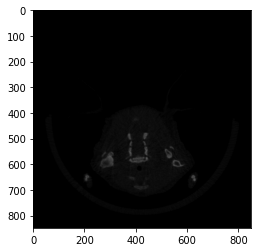

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC101/Il1r1_F_E64-CC101_Rec/Il1r1_F_E64-CC101__fantom2
END slice fantom2: Il1r1_F_E64-CC101__rec00000657.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1659
Count of head images: 521
Count of body images: 1185
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC102__rec00000405.bmp     0.111653
1     Il1r1_F_E64-CC102__rec00000406.bmp     0.115056
2     Il1r1_F_E64-CC102__rec00000407.bmp     0.113548
3     Il1r1_F_E64-CC102__rec00000408.bmp     0.111384
4     Il1r1_F_E64-CC102__rec00000409.bmp     0.110784
...                                  ...          ...
2147  Il1r1_F_E64-CC102__rec00002552.bmp     0.261318
2148  Il1r1_F_E64-CC102__rec00002553.bmp     0.260123
2149  Il1r1_F_E64-C

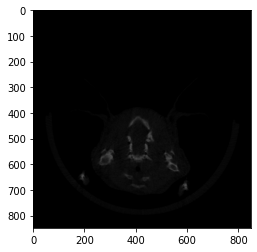

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC102/Il1r1_F_E64-CC102_Rec/Il1r1_F_E64-CC102__fantom2
END slice fantom2: Il1r1_F_E64-CC102__rec00000696.bmp
Index of last fanrom2 image in the full data frame: Int64Index([291], dtype='int64')
Index of predicted head slice: 1602
Count of head images: 550
Count of body images: 1131
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC117__rec00000417.bmp     0.110986
1     Il1r1_F_E64-CC117__rec00000418.bmp     0.111114
2     Il1r1_F_E64-CC117__rec00000419.bmp     0.110435
3     Il1r1_F_E64-CC117__rec00000420.bmp     0.109965
4     Il1r1_F_E64-CC117__rec00000421.bmp     0.110323
...                                  ...          ...
2123  Il1r1_F_E64-CC117__rec00002540.bmp     0.257654
2124  Il1r1_F_E64-CC117__rec00002541.bmp     0.256968
2125  Il1r1_F_E64-C

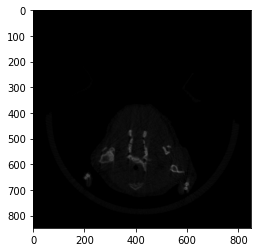

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC117/Il1r1_F_E64-CC117_Rec/Il1r1_F_E64-CC117__fantom2
END slice fantom2: Il1r1_F_E64-CC117__rec00000685.bmp
Index of last fanrom2 image in the full data frame: Int64Index([268], dtype='int64')
Index of predicted head slice: 1590
Count of head images: 538
Count of body images: 1142
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC122__rec00000398.bmp     0.109763
1     Il1r1_F_E64-CC122__rec00000399.bmp     0.109695
2     Il1r1_F_E64-CC122__rec00000400.bmp     0.112355
3     Il1r1_F_E64-CC122__rec00000401.bmp     0.111857
4     Il1r1_F_E64-CC122__rec00000402.bmp     0.111157
...                                  ...          ...
2171  Il1r1_F_E64-CC122__rec00002569.bmp     0.257913
2172  Il1r1_F_E64-CC122__rec00002570.bmp     0.257527
2173  Il1r1_F_E64-C

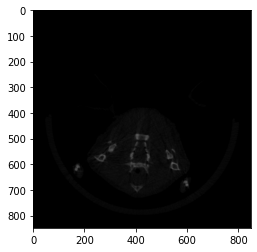

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC122/Il1r1_F_E64-CC122_Rec/Il1r1_F_E64-CC122__fantom2
END slice fantom2: Il1r1_F_E64-CC122__rec00000674.bmp
Index of last fanrom2 image in the full data frame: Int64Index([276], dtype='int64')
Index of predicted head slice: 1631
Count of head images: 545
Count of body images: 1175
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC123__rec00000399.bmp     0.109368
1     Il1r1_F_E64-CC123__rec00000400.bmp     0.110898
2     Il1r1_F_E64-CC123__rec00000401.bmp     0.112771
3     Il1r1_F_E64-CC123__rec00000402.bmp     0.112488
4     Il1r1_F_E64-CC123__rec00000403.bmp     0.112397
...                                  ...          ...
2122  Il1r1_F_E64-CC123__rec00002521.bmp     0.258586
2123  Il1r1_F_E64-CC123__rec00002522.bmp     0.259894
2124  Il1r1_F_E64-C

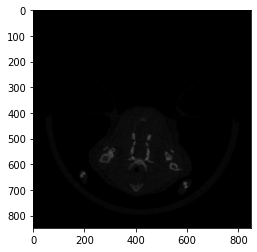

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC123/Il1r1_F_E64-CC123_Rec/Il1r1_F_E64-CC123__fantom2
END slice fantom2: Il1r1_F_E64-CC123__rec00000693.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1603
Count of head images: 524
Count of body images: 1129
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC132__rec00000379.bmp     0.110682
1     Il1r1_F_E64-CC132__rec00000380.bmp     0.105880
2     Il1r1_F_E64-CC132__rec00000381.bmp     0.108626
3     Il1r1_F_E64-CC132__rec00000382.bmp     0.109230
4     Il1r1_F_E64-CC132__rec00000383.bmp     0.108153
...                                  ...          ...
2144  Il1r1_F_E64-CC132__rec00002523.bmp     0.255579
2145  Il1r1_F_E64-CC132__rec00002524.bmp     0.255442
2146  Il1r1_F_E64-C

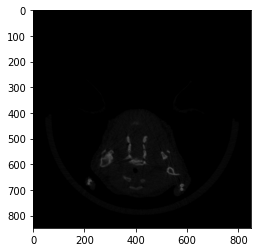

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC132/Il1r1_F_E64-CC132_Rec/Il1r1_F_E64-CC132__fantom2
END slice fantom2: Il1r1_F_E64-CC132__rec00000673.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1615
Count of head images: 534
Count of body images: 1141
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC144__rec00000425.bmp     0.116192
1     Il1r1_F_E64-CC144__rec00000426.bmp     0.115589
2     Il1r1_F_E64-CC144__rec00000427.bmp     0.116586
3     Il1r1_F_E64-CC144__rec00000428.bmp     0.115989
4     Il1r1_F_E64-CC144__rec00000429.bmp     0.111558
...                                  ...          ...
2095  Il1r1_F_E64-CC144__rec00002520.bmp     0.253173
2096  Il1r1_F_E64-CC144__rec00002521.bmp     0.253076
2097  Il1r1_F_E64-C

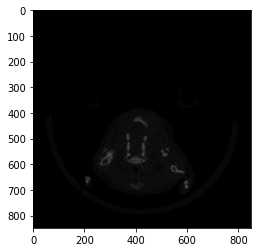

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC144/Il1r1_F_E64-CC144_Rec/Il1r1_F_E64-CC144__fantom2
END slice fantom2: Il1r1_F_E64-CC144__rec00000689.bmp
Index of last fanrom2 image in the full data frame: Int64Index([264], dtype='int64')
Index of predicted head slice: 1586
Count of head images: 514
Count of body images: 1142
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_F_E64-CC145__rec00000440.bmp     0.111702
1     Il1r1_F_E64-CC145__rec00000441.bmp     0.114116
2     Il1r1_F_E64-CC145__rec00000442.bmp     0.112884
3     Il1r1_F_E64-CC145__rec00000443.bmp     0.113371
4     Il1r1_F_E64-CC145__rec00000444.bmp     0.115534
...                                  ...          ...
2047  Il1r1_F_E64-CC145__rec00002487.bmp     0.250790
2048  Il1r1_F_E64-CC145__rec00002488.bmp     0.251010
2049  Il1r1_F_E64-C

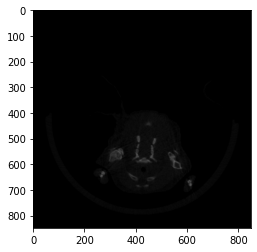

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC145/Il1r1_F_E64-CC145_Rec/Il1r1_F_E64-CC145__fantom2
END slice fantom2: Il1r1_F_E64-CC145__rec00000698.bmp
Index of last fanrom2 image in the full data frame: Int64Index([258], dtype='int64')
Index of predicted head slice: 1541
Count of head images: 511
Count of body images: 1103
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC099__rec00000400.bmp     0.112693
1     Il1r1_M_E64-CC099__rec00000401.bmp     0.113259
2     Il1r1_M_E64-CC099__rec00000402.bmp     0.110860
3     Il1r1_M_E64-CC099__rec00000403.bmp     0.110631
4     Il1r1_M_E64-CC099__rec00000404.bmp     0.109171
...                                  ...          ...
2138  Il1r1_M_E64-CC099__rec00002538.bmp     0.252642
2139  Il1r1_M_E64-CC099__rec00002539.bmp     0.253144
2140  Il1r1_M_E64-C

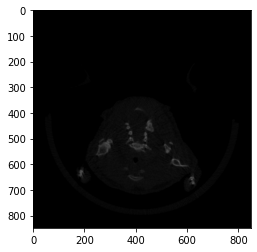

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC099/Il1r1_M_E64-CC099_Rec/Il1r1_M_E64-CC099__fantom2
END slice fantom2: Il1r1_M_E64-CC099__rec00000694.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1621
Count of head images: 522
Count of body images: 1147
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC100__rec00000400.bmp     0.115293
1     Il1r1_M_E64-CC100__rec00000401.bmp     0.118034
2     Il1r1_M_E64-CC100__rec00000402.bmp     0.118585
3     Il1r1_M_E64-CC100__rec00000403.bmp     0.120943
4     Il1r1_M_E64-CC100__rec00000404.bmp     0.118234
...                                  ...          ...
2133  Il1r1_M_E64-CC100__rec00002533.bmp     0.255231
2134  Il1r1_M_E64-CC100__rec00002534.bmp     0.256331
2135  Il1r1_M_E64-C

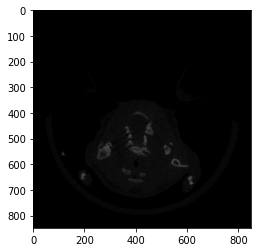

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC100/Il1r1_M_E64-CC100_Rec/Il1r1_M_E64-CC100__fantom2
END slice fantom2: Il1r1_M_E64-CC100__rec00000687.bmp
Index of last fanrom2 image in the full data frame: Int64Index([287], dtype='int64')
Index of predicted head slice: 1612
Count of head images: 526
Count of body images: 1145
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC105__rec00000399.bmp     0.119553
1     Il1r1_M_E64-CC105__rec00000400.bmp     0.119710
2     Il1r1_M_E64-CC105__rec00000401.bmp     0.119696
3     Il1r1_M_E64-CC105__rec00000402.bmp     0.118013
4     Il1r1_M_E64-CC105__rec00000403.bmp     0.116342
...                                  ...          ...
2152  Il1r1_M_E64-CC105__rec00002551.bmp     0.256224
2153  Il1r1_M_E64-CC105__rec00002552.bmp     0.257553
2154  Il1r1_M_E64-C

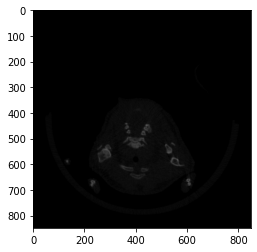

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC105/Il1r1_M_E64-CC105_Rec/Il1r1_M_E64-CC105__fantom2
END slice fantom2: Il1r1_M_E64-CC105__rec00000693.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1628
Count of head images: 529
Count of body images: 1154
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC120__rec00000400.bmp     0.124128
1     Il1r1_M_E64-CC120__rec00000401.bmp     0.120456
2     Il1r1_M_E64-CC120__rec00000402.bmp     0.117764
3     Il1r1_M_E64-CC120__rec00000403.bmp     0.120777
4     Il1r1_M_E64-CC120__rec00000404.bmp     0.120575
...                                  ...          ...
2158  Il1r1_M_E64-CC120__rec00002558.bmp     0.262030
2159  Il1r1_M_E64-CC120__rec00002559.bmp     0.263876
2160  Il1r1_M_E64-C

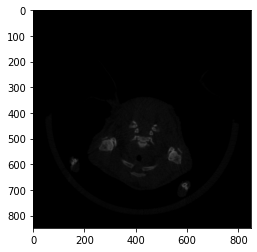

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC120/Il1r1_M_E64-CC120_Rec/Il1r1_M_E64-CC120__fantom2
END slice fantom2: Il1r1_M_E64-CC120__rec00000688.bmp
Index of last fanrom2 image in the full data frame: Int64Index([288], dtype='int64')
Index of predicted head slice: 1638
Count of head images: 525
Count of body images: 1170
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC121__rec00000410.bmp     0.117488
1     Il1r1_M_E64-CC121__rec00000411.bmp     0.115322
2     Il1r1_M_E64-CC121__rec00000412.bmp     0.116509
3     Il1r1_M_E64-CC121__rec00000413.bmp     0.119028
4     Il1r1_M_E64-CC121__rec00000414.bmp     0.120255
...                                  ...          ...
2134  Il1r1_M_E64-CC121__rec00002544.bmp     0.345012
2135  Il1r1_M_E64-CC121__rec00002545.bmp     0.336779
2136  Il1r1_M_E64-C

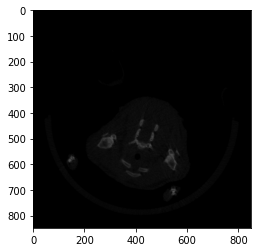

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC121/Il1r1_M_E64-CC121_Rec/Il1r1_M_E64-CC121__fantom2
END slice fantom2: Il1r1_M_E64-CC121__rec00000675.bmp
Index of last fanrom2 image in the full data frame: Int64Index([265], dtype='int64')
Index of predicted head slice: 1653
Count of head images: 486
Count of body images: 1208
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC131__rec00000425.bmp     0.116616
1     Il1r1_M_E64-CC131__rec00000426.bmp     0.115797
2     Il1r1_M_E64-CC131__rec00000427.bmp     0.116290
3     Il1r1_M_E64-CC131__rec00000428.bmp     0.115672
4     Il1r1_M_E64-CC131__rec00000429.bmp     0.118721
...                                  ...          ...
2142  Il1r1_M_E64-CC131__rec00002567.bmp     0.255212
2143  Il1r1_M_E64-CC131__rec00002568.bmp     0.255863
2144  Il1r1_M_E64-C

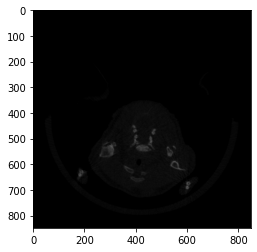

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC131/Il1r1_M_E64-CC131_Rec/Il1r1_M_E64-CC131__fantom2
END slice fantom2: Il1r1_M_E64-CC131__rec00000686.bmp
Index of last fanrom2 image in the full data frame: Int64Index([261], dtype='int64')
Index of predicted head slice: 1608
Count of head images: 539
Count of body images: 1167
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC141__rec00000425.bmp     0.119899
1     Il1r1_M_E64-CC141__rec00000426.bmp     0.120461
2     Il1r1_M_E64-CC141__rec00000427.bmp     0.119429
3     Il1r1_M_E64-CC141__rec00000428.bmp     0.121212
4     Il1r1_M_E64-CC141__rec00000429.bmp     0.122752
...                                  ...          ...
2057  Il1r1_M_E64-CC141__rec00002482.bmp     0.322836
2058  Il1r1_M_E64-CC141__rec00002483.bmp     0.309246
2059  Il1r1_M_E64-C

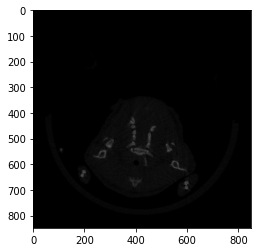

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC141/Il1r1_M_E64-CC141_Rec/Il1r1_M_E64-CC141__fantom2
END slice fantom2: Il1r1_M_E64-CC141__rec00000681.bmp
Index of last fanrom2 image in the full data frame: Int64Index([256], dtype='int64')
Index of predicted head slice: 1577
Count of head images: 485
Count of body images: 1141
Folders were created
Images were copied to the new folders
                              Image_name  Propability
0     Il1r1_M_E64-CC143__rec00000399.bmp     0.112483
1     Il1r1_M_E64-CC143__rec00000400.bmp     0.112976
2     Il1r1_M_E64-CC143__rec00000401.bmp     0.116341
3     Il1r1_M_E64-CC143__rec00000402.bmp     0.117330
4     Il1r1_M_E64-CC143__rec00000403.bmp     0.115747
...                                  ...          ...
2207  Il1r1_M_E64-CC143__rec00002606.bmp     0.261813
2208  Il1r1_M_E64-CC143__rec00002607.bmp     0.261621
2209  Il1r1_M_E64-C

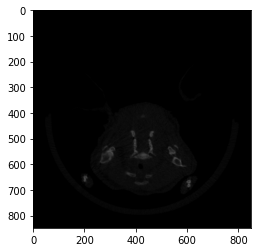

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC143/Il1r1_M_E64-CC143_Rec/Il1r1_M_E64-CC143__fantom2
END slice fantom2: Il1r1_M_E64-CC143__rec00000676.bmp
Index of last fanrom2 image in the full data frame: Int64Index([277], dtype='int64')
Index of predicted head slice: 1666
Count of head images: 546
Count of body images: 1209
Folders were created
Images were copied to the new folders
                             Image_name  Propability
0     Sord_F_E64-CC096__rec00000405.bmp     0.118560
1     Sord_F_E64-CC096__rec00000406.bmp     0.116401
2     Sord_F_E64-CC096__rec00000407.bmp     0.114586
3     Sord_F_E64-CC096__rec00000408.bmp     0.112156
4     Sord_F_E64-CC096__rec00000409.bmp     0.114214
...                                 ...          ...
2113  Sord_F_E64-CC096__rec00002518.bmp     0.258138
2114  Sord_F_E64-CC096__rec00002519.bmp     0.256230
2115  Sord_F_E64-CC096__rec0

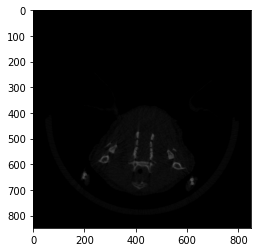

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC096/Sord_F_E64-CC096_Rec/Sord_F_E64-CC096__fantom2
END slice fantom2: Sord_F_E64-CC096__rec00000675.bmp
Index of last fanrom2 image in the full data frame: Int64Index([270], dtype='int64')
Index of predicted head slice: 1598
Count of head images: 520
Count of body images: 1148
Folders were created
Images were copied to the new folders
                             Image_name  Propability
0     Sord_F_E64-CC097__rec00000400.bmp     0.111135
1     Sord_F_E64-CC097__rec00000401.bmp     0.115056
2     Sord_F_E64-CC097__rec00000402.bmp     0.113690
3     Sord_F_E64-CC097__rec00000403.bmp     0.115035
4     Sord_F_E64-CC097__rec00000404.bmp     0.113437
...                                 ...          ...
2178  Sord_F_E64-CC097__rec00002578.bmp     0.267032
2179  Sord_F_E64-CC097__rec00002579.bmp     0.264922
2180  Sord_F_E64-CC097__rec00002

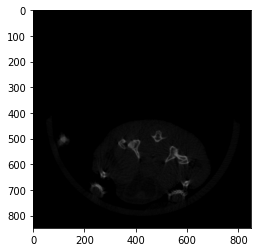

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__fantom2
END slice fantom2: Sord_F_E64-CC097__rec00000686.bmp
Index of last fanrom2 image in the full data frame: Int64Index([286], dtype='int64')
Index of predicted head slice: 770
Count of head images: 1413
Count of body images: 304
Folders were created
Images were copied to the new folders
                             Image_name  Propability
0     Sord_F_E64-CC153__rec00000400.bmp     0.113406
1     Sord_F_E64-CC153__rec00000401.bmp     0.113776
2     Sord_F_E64-CC153__rec00000402.bmp     0.113662
3     Sord_F_E64-CC153__rec00000403.bmp     0.115425
4     Sord_F_E64-CC153__rec00000404.bmp     0.114510
...                                 ...          ...
2117  Sord_F_E64-CC153__rec00002517.bmp     0.260024
2118  Sord_F_E64-CC153__rec00002518.bmp     0.257797
2119  Sord_F_E64-CC153__rec000025

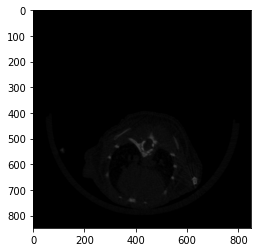

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC153/Sord_F_E64-CC153_Rec/Sord_F_E64-CC153__fantom2
END slice fantom2: Sord_F_E64-CC153__rec00000690.bmp
Index of last fanrom2 image in the full data frame: Int64Index([290], dtype='int64')
Index of predicted head slice: 1428
Count of head images: 694
Count of body images: 958
Folders were created
Images were copied to the new folders
                             Image_name  Propability
0     Sord_M_E64-CC152__rec00000435.bmp     0.120334
1     Sord_M_E64-CC152__rec00000436.bmp     0.124096
2     Sord_M_E64-CC152__rec00000437.bmp     0.125171
3     Sord_M_E64-CC152__rec00000438.bmp     0.128267
4     Sord_M_E64-CC152__rec00000439.bmp     0.126567
...                                 ...          ...
2093  Sord_M_E64-CC152__rec00002528.bmp     0.259029
2094  Sord_M_E64-CC152__rec00002529.bmp     0.260062
2095  Sord_M_E64-CC152__rec000025

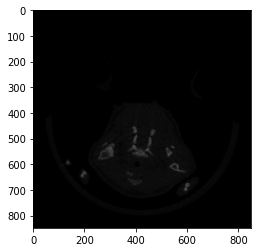

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_M_E64-CC152/Sord_M_E64-CC152_Rec/Sord_M_E64-CC152__fantom2
END slice fantom2: Sord_M_E64-CC152__rec00000699.bmp
Index of last fanrom2 image in the full data frame: Int64Index([264], dtype='int64')
Index of predicted head slice: 1572
Count of head images: 526
Count of body images: 1128
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-11784__rec00000390.bmp     0.123395
1     wt_F_82Z-11784__rec00000391.bmp     0.121749
2     wt_F_82Z-11784__rec00000392.bmp     0.120555
3     wt_F_82Z-11784__rec00000393.bmp     0.117939
4     wt_F_82Z-11784__rec00000394.bmp     0.115844
...                               ...          ...
2169  wt_F_82Z-11784__rec00002559.bmp     0.257986
2170  wt_F_82Z-11784__rec00002560.bmp     0.259010
2171  wt_F_82Z-11784__rec00002561.bmp     0.262009

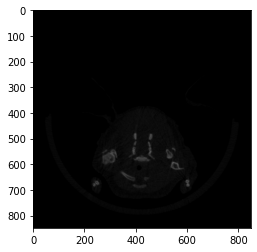

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-11784/wt_F_82Z-11784_Rec/wt_F_82Z-11784__fantom2
END slice fantom2: wt_F_82Z-11784__rec00000684.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1634
Count of head images: 540
Count of body images: 1160
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-11785__rec00000415.bmp     0.112703
1     wt_F_82Z-11785__rec00000416.bmp     0.115372
2     wt_F_82Z-11785__rec00000417.bmp     0.114571
3     wt_F_82Z-11785__rec00000418.bmp     0.114689
4     wt_F_82Z-11785__rec00000419.bmp     0.113406
...                               ...          ...
2115  wt_F_82Z-11785__rec00002530.bmp     0.259947
2116  wt_F_82Z-11785__rec00002531.bmp     0.259406
2117  wt_F_82Z-11785__rec00002532.bmp     0.261991
2118  w

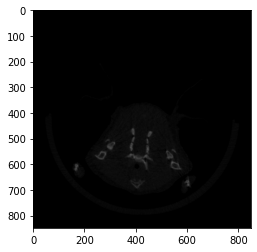

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-11785/wt_F_82Z-11785_Rec/wt_F_82Z-11785__fantom2
END slice fantom2: wt_F_82Z-11785__rec00000686.bmp
Index of last fanrom2 image in the full data frame: Int64Index([271], dtype='int64')
Index of predicted head slice: 1585
Count of head images: 535
Count of body images: 1134
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-CH156__rec00000400.bmp     0.111254
1     wt_F_82Z-CH156__rec00000401.bmp     0.108989
2     wt_F_82Z-CH156__rec00000402.bmp     0.108574
3     wt_F_82Z-CH156__rec00000403.bmp     0.111268
4     wt_F_82Z-CH156__rec00000404.bmp     0.111336
...                               ...          ...
2183  wt_F_82Z-CH156__rec00002583.bmp     0.254947
2184  wt_F_82Z-CH156__rec00002584.bmp     0.253945
2185  wt_F_82Z-CH156__rec00002585.bmp     0.254742
2186  w

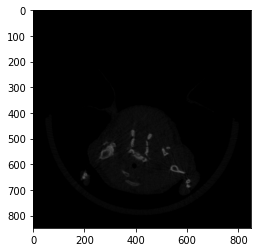

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH156/wt_F_82Z-CH156_Rec/wt_F_82Z-CH156__fantom2
END slice fantom2: wt_F_82Z-CH156__rec00000672.bmp
Index of last fanrom2 image in the full data frame: Int64Index([272], dtype='int64')
Index of predicted head slice: 1664
Count of head images: 524
Count of body images: 1212
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-CH157__rec00000415.bmp     0.110234
1     wt_F_82Z-CH157__rec00000416.bmp     0.110474
2     wt_F_82Z-CH157__rec00000417.bmp     0.111823
3     wt_F_82Z-CH157__rec00000418.bmp     0.112046
4     wt_F_82Z-CH157__rec00000419.bmp     0.112476
...                               ...          ...
2124  wt_F_82Z-CH157__rec00002539.bmp     0.255146
2125  wt_F_82Z-CH157__rec00002540.bmp     0.254673
2126  wt_F_82Z-CH157__rec00002541.bmp     0.257574
2127  w

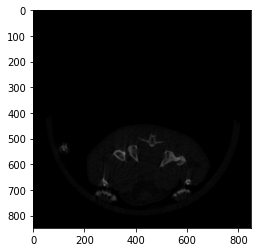

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH157/wt_F_82Z-CH157_Rec/wt_F_82Z-CH157__fantom2
END slice fantom2: wt_F_82Z-CH157__rec00000688.bmp
Index of last fanrom2 image in the full data frame: Int64Index([273], dtype='int64')
Index of predicted head slice: 807
Count of head images: 1322
Count of body images: 354
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-CH158__rec00000385.bmp     0.110764
1     wt_F_82Z-CH158__rec00000386.bmp     0.111445
2     wt_F_82Z-CH158__rec00000387.bmp     0.109156
3     wt_F_82Z-CH158__rec00000388.bmp     0.110948
4     wt_F_82Z-CH158__rec00000389.bmp     0.111096
...                               ...          ...
2183  wt_F_82Z-CH158__rec00002568.bmp     0.253610
2184  wt_F_82Z-CH158__rec00002569.bmp     0.255129
2185  wt_F_82Z-CH158__rec00002570.bmp     0.253819
2186  wt

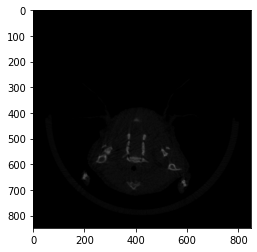

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH158/wt_F_82Z-CH158_Rec/wt_F_82Z-CH158__fantom2
END slice fantom2: wt_F_82Z-CH158__rec00000669.bmp
Index of last fanrom2 image in the full data frame: Int64Index([284], dtype='int64')
Index of predicted head slice: 1666
Count of head images: 522
Count of body images: 1202
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-CH159__rec00000409.bmp     0.109942
1     wt_F_82Z-CH159__rec00000410.bmp     0.108995
2     wt_F_82Z-CH159__rec00000411.bmp     0.110515
3     wt_F_82Z-CH159__rec00000412.bmp     0.115550
4     wt_F_82Z-CH159__rec00000413.bmp     0.113029
...                               ...          ...
2117  wt_F_82Z-CH159__rec00002526.bmp     0.254832
2118  wt_F_82Z-CH159__rec00002527.bmp     0.254190
2119  wt_F_82Z-CH159__rec00002528.bmp     0.253186
2120  w

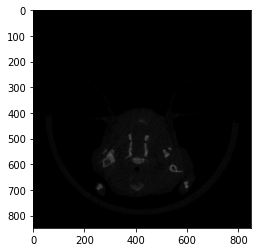

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH159/wt_F_82Z-CH159_Rec/wt_F_82Z-CH159__fantom2
END slice fantom2: wt_F_82Z-CH159__rec00000685.bmp
Index of last fanrom2 image in the full data frame: Int64Index([276], dtype='int64')
Index of predicted head slice: 1617
Count of head images: 505
Count of body images: 1161
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_F_82Z-CH160__rec00000385.bmp     0.108430
1     wt_F_82Z-CH160__rec00000386.bmp     0.108771
2     wt_F_82Z-CH160__rec00000387.bmp     0.109725
3     wt_F_82Z-CH160__rec00000388.bmp     0.110515
4     wt_F_82Z-CH160__rec00000389.bmp     0.112186
...                               ...          ...
2172  wt_F_82Z-CH160__rec00002557.bmp     0.255018
2173  wt_F_82Z-CH160__rec00002558.bmp     0.252848
2174  wt_F_82Z-CH160__rec00002559.bmp     0.252934
2175  w

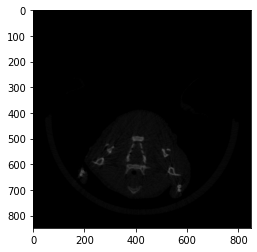

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__fantom2
END slice fantom2: wt_F_82Z-CH160__rec00000679.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1630
Count of head images: 547
Count of body images: 1156
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-11782__rec00000355.bmp     0.115815
1     wt_M_82Z-11782__rec00000356.bmp     0.114145
2     wt_M_82Z-11782__rec00000357.bmp     0.114928
3     wt_M_82Z-11782__rec00000358.bmp     0.111214
4     wt_M_82Z-11782__rec00000359.bmp     0.111753
...                               ...          ...
2235  wt_M_82Z-11782__rec00002590.bmp     0.263330
2236  wt_M_82Z-11782__rec00002591.bmp     0.261269
2237  wt_M_82Z-11782__rec00002592.bmp     0.259421
2238  w

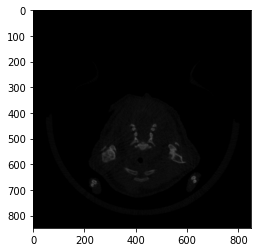

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11782/wt_M_82Z-11782_Rec/wt_M_82Z-11782__fantom2
END slice fantom2: wt_M_82Z-11782__rec00000649.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1706
Count of head images: 534
Count of body images: 1232
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-11783__rec00000395.bmp     0.119035
1     wt_M_82Z-11783__rec00000396.bmp     0.117024
2     wt_M_82Z-11783__rec00000397.bmp     0.116868
3     wt_M_82Z-11783__rec00000398.bmp     0.116715
4     wt_M_82Z-11783__rec00000399.bmp     0.119624
...                               ...          ...
2149  wt_M_82Z-11783__rec00002544.bmp     0.257649
2150  wt_M_82Z-11783__rec00002545.bmp     0.257415
2151  wt_M_82Z-11783__rec00002546.bmp     0.255799
2152  w

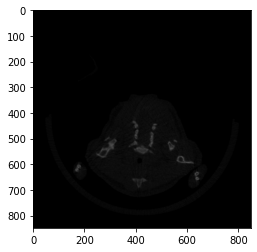

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11783/wt_M_82Z-11783_Rec/wt_M_82Z-11783__fantom2
END slice fantom2: wt_M_82Z-11783__rec00000674.bmp
Index of last fanrom2 image in the full data frame: Int64Index([279], dtype='int64')
Index of predicted head slice: 1647
Count of head images: 507
Count of body images: 1188
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-CH142__rec00000404.bmp     0.112007
1     wt_M_82Z-CH142__rec00000405.bmp     0.111114
2     wt_M_82Z-CH142__rec00000406.bmp     0.111745
3     wt_M_82Z-CH142__rec00000407.bmp     0.111353
4     wt_M_82Z-CH142__rec00000408.bmp     0.112565
...                               ...          ...
2142  wt_M_82Z-CH142__rec00002546.bmp     0.253810
2143  wt_M_82Z-CH142__rec00002547.bmp     0.253867
2144  wt_M_82Z-CH142__rec00002548.bmp     0.255361
2145  w

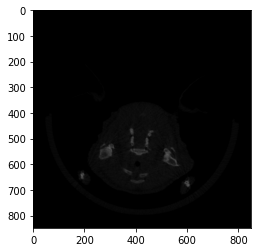

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-CH142/wt_M_82Z-CH142_Rec/wt_M_82Z-CH142__fantom2
END slice fantom2: wt_M_82Z-CH142__rec00000671.bmp
Index of last fanrom2 image in the full data frame: Int64Index([267], dtype='int64')
Index of predicted head slice: 1628
Count of head images: 519
Count of body images: 1181
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-CH143__rec00000430.bmp     0.113758
1     wt_M_82Z-CH143__rec00000431.bmp     0.115167
2     wt_M_82Z-CH143__rec00000432.bmp     0.112846
3     wt_M_82Z-CH143__rec00000433.bmp     0.110699
4     wt_M_82Z-CH143__rec00000434.bmp     0.111419
...                               ...          ...
2112  wt_M_82Z-CH143__rec00002542.bmp     0.252236
2113  wt_M_82Z-CH143__rec00002543.bmp     0.252911
2114  wt_M_82Z-CH143__rec00002544.bmp     0.252444
2115  w

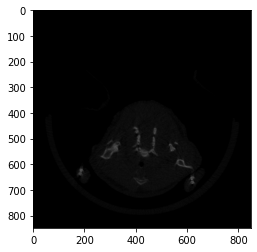

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-CH143/wt_M_82Z-CH143_Rec/wt_M_82Z-CH143__fantom2
END slice fantom2: wt_M_82Z-CH143__rec00000686.bmp
Index of last fanrom2 image in the full data frame: Int64Index([256], dtype='int64')
Index of predicted head slice: 1590
Count of head images: 527
Count of body images: 1154
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-CH144__rec00000400.bmp     0.105239
1     wt_M_82Z-CH144__rec00000401.bmp     0.106676
2     wt_M_82Z-CH144__rec00000402.bmp     0.106000
3     wt_M_82Z-CH144__rec00000403.bmp     0.105619
4     wt_M_82Z-CH144__rec00000404.bmp     0.106886
...                               ...          ...
2082  wt_M_82Z-CH144__rec00002482.bmp     0.247653
2083  wt_M_82Z-CH144__rec00002483.bmp     0.248468
2084  wt_M_82Z-CH144__rec00002484.bmp     0.249451
2085  w

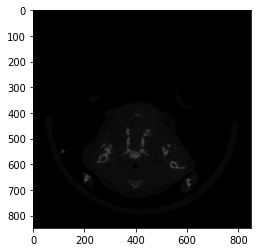

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-CH144/wt_M_82Z-CH144_Rec/wt_M_82Z-CH144__fantom2
END slice fantom2: wt_M_82Z-CH144__rec00000694.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1568
Count of head images: 519
Count of body images: 1094
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-CH154__rec00000420.bmp     0.105832
1     wt_M_82Z-CH154__rec00000421.bmp     0.104840
2     wt_M_82Z-CH154__rec00000422.bmp     0.107112
3     wt_M_82Z-CH154__rec00000423.bmp     0.107335
4     wt_M_82Z-CH154__rec00000424.bmp     0.106969
...                               ...          ...
2155  wt_M_82Z-CH154__rec00002575.bmp     0.256717
2156  wt_M_82Z-CH154__rec00002576.bmp     0.258926
2157  wt_M_82Z-CH154__rec00002577.bmp     0.259073
2158  w

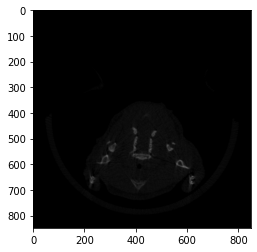

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-CH154/wt_M_82Z-CH154_Rec/wt_M_82Z-CH154__fantom2
END slice fantom2: wt_M_82Z-CH154__rec00000686.bmp
Index of last fanrom2 image in the full data frame: Int64Index([266], dtype='int64')
Index of predicted head slice: 1647
Count of head images: 513
Count of body images: 1201
Folders were created
Images were copied to the new folders
                           Image_name  Propability
0     wt_M_82Z-CH155__rec00000415.bmp     0.104072
1     wt_M_82Z-CH155__rec00000416.bmp     0.104087
2     wt_M_82Z-CH155__rec00000417.bmp     0.104987
3     wt_M_82Z-CH155__rec00000418.bmp     0.103577
4     wt_M_82Z-CH155__rec00000419.bmp     0.106599
...                               ...          ...
2064  wt_M_82Z-CH155__rec00002479.bmp     0.260411
2065  wt_M_82Z-CH155__rec00002480.bmp     0.242881
2066  wt_M_82Z-CH155__rec00002481.bmp     0.242933
2067  w

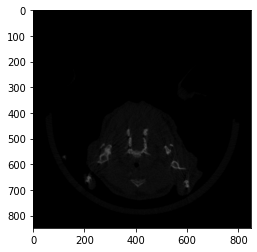

Path to the fantom2 folder: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-CH155/wt_M_82Z-CH155_Rec/wt_M_82Z-CH155__fantom2
END slice fantom2: wt_M_82Z-CH155__rec00000695.bmp
Index of last fanrom2 image in the full data frame: Int64Index([280], dtype='int64')
Index of predicted head slice: 1571
Count of head images: 498
Count of body images: 1111
Folders were created
Images were copied to the new folders
############################This step took 12028.154461860657 seconds###########################
Il1r1_F_E64-CC101
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC101/Il1r1_F_E64-CC101_Rec/Il1r1_F_E64-CC101__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC101/Il1r1_F_E64-CC101_Rec/Il1r1_F_E64-CC101__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimagi

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC099/Il1r1_M_E64-CC099_Rec/Il1r1_M_E64-CC099__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC099/Il1r1_M_E64-CC099_Rec/Il1r1_M_E64-CC099__mask_edited
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC099/Il1r1_M_E64-CC099_Rec/Il1r1_M_E64-CC099__predictions
Old folder with masks was deleted: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC099/Il1r1_M_E64-CC099_Rec/Il1r1_M_E64-CC099__mask
Il1r1_M_E64-CC100
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_M_E64-CC100/Il1r1_M_E64-CC100_Rec/Il1r1_M_E64-CC100__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimagi

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__mask_edited
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__predictions
Old folder with masks was deleted: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__mask
Sord_F_E64-CC153
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC153/Sord_F_E64-CC153_Rec/Sord_F_E64-CC153__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morp

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__mask
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__mask_edited
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__predictions
Old folder with masks was deleted: /home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__mask
wt_M_82Z-11782
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11782/wt_M_82Z-11782_Rec/wt_M_82Z-11782__body
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_I

Il1r1_F_E64-CC122
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC122/Il1r1_F_E64-CC122_Rec/Il1r1_F_E64-CC122__fantom1
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC122/Il1r1_F_E64-CC122_Rec/Il1r1_F_E64-CC122__fantom2
Il1r1_F_E64-CC123
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC123/Il1r1_F_E64-CC123_Rec/Il1r1_F_E64-CC123__fantom1
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC123/Il1r1_F_E64-CC123_Rec/Il1r1_F_E64-CC123__fantom2
Il1r1_F_E64-CC132
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC132/Il1r1_F_E64-CC132_Rec/Il1r1_F_E64-CC132__fantom1
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioima

/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH159/wt_F_82Z-CH159_Rec/wt_F_82Z-CH159__fantom2
wt_F_82Z-CH160
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__fantom1
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160__fantom2
wt_M_82Z-11782
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11782/wt_M_82Z-11782_Rec/wt_M_82Z-11782__fantom1
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11782/wt_M_82Z-11782_Rec/wt_M_82Z-11782__fantom2
wt_M_82Z-11783
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1

BMD13 BMD14TMD30 TMD31
0.07332727059208406 0.07332727059208406 0.4370374965381207 0.4458261800327653
0.015450775561890366 0.0315021895580353 0.00977908131877967 0.021455208141362165
0.07332727059208406 0.4370374965381207
Il1r1_F_E64-CC144_~0000000000.tif 2023-01-02
Il1r1_F_E64-CC144_~0000000001.tif 2023-01-02
Il1r1_F_E64-CC144_~0000000002.tif 2023-01-02
Il1r1_F_E64-CC144_~0000000003.tif 2023-01-02
Il1r1_F_E64-CC144_~0000000004.tif 2023-01-02
Il1r1_F_E64-CC144_~0000000005.tif 2023-01-02
2023-01-02
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC144/Il1r1_F_E64-CC144_Rec/Il1r1_F_E64-CC144.csv
Il1r1_F_E64-CC145
E64-CC145
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Il1r1_F_E64-CC145/Il1r1_F_E64-CC145_Rec/Il1r1_F_E64-CC145__predictions
BMD13 BMD14TMD30 TMD31
0.07642092684005464 0.07642092684005464 0.441605740148427 0.4504933337553059
0.015445376

BMD13 BMD14TMD30 TMD31
0.07393455885572182 0.07393455885572182 0.45060729297292146 0.4594019112672011
0.015399318653791518 0.03139276302921023 0.009767532975042377 0.021816121816723006
0.07393455885572182 0.45060729297292146
Sord_F_E64-CC096_~0000000000.tif 2023-01-02
Sord_F_E64-CC096_~0000000001.tif 2023-01-02
Sord_F_E64-CC096_~0000000002.tif 2023-01-02
Sord_F_E64-CC096_~0000000003.tif 2023-01-02
Sord_F_E64-CC096_~0000000004.tif 2023-01-02
Sord_F_E64-CC096_~0000000005.tif 2023-01-02
2023-01-02
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC096/Sord_F_E64-CC096_Rec/Sord_F_E64-CC096.csv
Sord_F_E64-CC097
E64-CC097
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/Sord_F_E64-CC097/Sord_F_E64-CC097_Rec/Sord_F_E64-CC097__predictions
BMD13 BMD14TMD30 TMD31
0.1316758165235718 0.1316758165235718 0.49447727960722626 0.5034943198539605
0.015364747676131621

BMD13 BMD14TMD30 TMD31
0.06875640740204456 0.06875640740204456 0.4434187768015211 0.45224265891924575
0.015638773556565646 0.03196685031222369 0.00972005497374438 0.021955086823767102
0.06875640740204456 0.4434187768015211
wt_F_82Z-CH160_~0000000000.tif 2023-01-02
wt_F_82Z-CH160_~0000000001.tif 2023-01-02
wt_F_82Z-CH160_~0000000002.tif 2023-01-02
wt_F_82Z-CH160_~0000000003.tif 2023-01-02
wt_F_82Z-CH160_~0000000004.tif 2023-01-02
wt_F_82Z-CH160_~0000000005.tif 2023-01-02
2023-01-02
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_F_82Z-CH160/wt_F_82Z-CH160_Rec/wt_F_82Z-CH160.csv
wt_M_82Z-11782
82Z-11782
/home/castrone/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230102c271_Il1r1 & Sord & wt/wt_M_82Z-11782/wt_M_82Z-11782_Rec/wt_M_82Z-11782__predictions
BMD13 BMD14TMD30 TMD31
0.0704758244825551 0.0704758244825551 0.4452482171215136 0.4540887428431284
0.015406359194169992 0.03137567139865151 0.009672

In [75]:
########################################################################################################## Part 1 for 1278: function to detect the fantom s##############################################

print('############## Part 1: function to detect the phantoms - Running ###########')
init = time.time()

visited_path = []
failed_path = []
for path in df_cohort_1278['PATH']:
    
    isExist = os.path.exists(cohort_folder+'/'+'csv_files')
    if not isExist:
        os.mkdir(cohort_folder+'/'+'csv_files')
    detect_circle(path)

all_files = glob.glob(os.path.join(cohort_folder+'/'+'csv_files', "*.csv"))
df_from_each_file = (pd.read_csv(f, sep=',') for f in all_files)
df_merged   = pd.concat(df_from_each_file, ignore_index=True)
df_merged.to_csv(cohort_folder+'/'+"fantoms_count.csv",index=False)
shutil.rmtree(cohort_folder+'/'+'csv_files')

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 1 - Finished ###########')
######################################################################################################## Part 2 for 1278: function to predict the head slice ############################################
print('############## Part 2: function to predict the head slice - Running ###########')
init = time.time()

for path in df_cohort_1278['PATH']:
    predict_head_slice_1278(path)

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 2 - Finished ###########')
######################################################################################################### Part 3 for 1278: *function for masking body without head #######################################
print('############## Part 3: function for masking body without head - Running ###########')
init = time.time()

for path in df_cohort_1278['PATH']:
    selected_row = df_cohort_1278.loc[df_cohort_1278['PATH'] == path]
    masking_predict_1278(path, int(selected_row['IMAGE_WIDTH']), int(selected_row['IMAGE_HEIGHT']))

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 3 - Finished ###########')
######################################################################################################## Part 4 for 1278: function for masking fantoms to get ROI #######################################
print('############## Part 4: function for masking fantoms to get ROI - Running ###########')
init = time.time()

for path in df_cohort_1278['PATH']:
    mask_fantoms(path)  

end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 4 - Finished ###########')
######################################################################################################## Part 5: function for BMD and TMD calculation ###################################################
print('############## Part 5: function for BMD and TMD calculation - Running ###########')
init = time.time()

for path in df_cohort_1278['PATH']:
    isBMD_TMD = os.path.exists(cohort_folder+'/'+'BMD_TMD') 
    if not isBMD_TMD:
        os.mkdir(cohort_folder+'/'+'BMD_TMD')
    TMD_BMD_1278(path)
    
end = time.time()
print("############################This step took " + str(end-init) + " seconds###########################")
print('############## Part 5 - Finished ###########')